## Homework 5: Transfer Learning with MobileNetV2 on the Intel Image Dataset

**Due: Sunday, October 4, 2026, at 11:59 PM ET**

There is a grace period until **2:00 AM ET**. After that, late submissions are penalized **10% for each 24-hour period**. After **5 days**, the score is 0.

In this assignment, you will use a modern pretrained CNN, **MobileNetV2**, to classify the **Intel Image Dataset**, which contains 6 scene classes.

You will begin by using MobileNetV2 as a **frozen feature extractor**, training only a new classification head. You will then explore progressively more flexible transfer-learning strategies by making all or part of the pretrained backbone trainable.

To make experimentation practical, the notebook provides a `DATA_FRACTION` setting. During development, you may use a smaller fraction of the dataset to test ideas and compare configurations more quickly. Before recording your final results, set:

```python
DATA_FRACTION = 1.0
```

and rerun the complete notebook using the full dataset.

Because MobileNetV2 was pretrained on ImageNet, the images are processed using `mobilenet_v2.preprocess_input`, which scales the input pixels to the range expected by the pretrained network.

The goal is to understand **why transfer learning works**, how to design a useful **classification head**, and how choices such as **learning rate**, **learning-rate control with `ReduceLROnPlateau`**, **regularization**, and **which pretrained layers are allowed to change** affect model performance.

### Learning Objectives

By the end of this homework, you should be able to:

* Use a pretrained CNN as a **frozen feature extractor**.
* Design and compare different **classification heads** on top of a pretrained backbone.
* Experiment efficiently using a reduced dataset before running final models on the full dataset.
* Understand the difference between a **frozen backbone** and making some or all pretrained layers trainable.
* Use practical training controls including:

  * fixed **learning rates**,
  * `ReduceLROnPlateau`,
  * `EarlyStopping`,
  * **Dropout** and **L2 regularization**,
  * and **Batch Normalization** in classification heads.
* Compare strategies that make:

  * the **entire backbone** trainable,
  * only the **last N layers** trainable,
  * or only the **top K MobileNetV2 blocks** trainable.

### Baseline Model

The starting backbone is:

```python
MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg"
)
```

With `pooling="avg"`, MobileNetV2 already applies **Global Average Pooling** and outputs a **1280-dimensional feature vector** for each image.

The baseline classification head consists of a single:

```python
Dense(num_classes, activation="softmax")
```

layer for the 6 Intel classes.

**Do not add another pooling layer when `pooling="avg"` is used.**

### The Five Problems

1. **Problem 1 — Frozen Backbone:**
   Keep MobileNetV2 frozen and redesign only the **classification head**. Try at least three head designs and experiment with training hyperparameters.

2. **Problem 2 — Fully Trainable Backbone:**
   Use one of your best head architectures from Problem 1, make the **entire MobileNetV2 backbone trainable**, and experiment with appropriately small learning rates and other training choices.

3. **Problem 3 — Unfreeze the Last N Layers:**
   Keep most of MobileNetV2 frozen while allowing only the **last N layers** to be updated.

4. **Problem 4 — Unfreeze the Top K Blocks:**
   Instead of selecting individual layers, make only the **top K MobileNetV2 blocks or stages** trainable and compare the results.

5. **Problem 5 -- Final Reflection**

Use your **HW4 CNN results as a reference point**. Transfer learning may or may not outperform every model you developed in HW4; the important goal is to understand how the different transfer-learning strategies affect training behavior and model performance.



## 1. Setup and Data Loading


In [5]:
# -------- Standard library --------
import os
import time
import random
from collections import Counter

# Quiet TensorFlow logs (set BEFORE importing TF)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# -------- Third-party --------
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import kagglehub

import tensorflow as tf
from tensorflow.keras import layers,models, callbacks, regularizers, initializers
from tensorflow.keras.callbacks import Callback,EarlyStopping,ReduceLROnPlateau
from tensorflow.keras.layers import (
    BatchNormalization,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    GlobalAveragePooling2D,
    GlobalMaxPooling2D,
    Input,
    MaxPooling2D,
    ReLU,
    SeparableConv2D,
)

from tensorflow.keras.applications import mobilenet_v2
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.preprocessing.image import load_img, img_to_array



he = initializers.HeNormal()
l2reg = regularizers.l2(1e-4)

# Reproducibility settings
# -------------------------
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
tf.keras.utils.set_random_seed(random_seed)

def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))


### Utility function to plot learning curves and keep track of all results

- Call `print_results()` to see listing of all results logged so far

In [6]:

def plot_learning_curves(hist, title, verbose=True):
    
    val_losses = hist.history['val_loss']
    min_val_loss = min(val_losses)
    min_val_epoch = val_losses.index(min_val_loss)
    val_acc_at_min_loss = hist.history['val_accuracy'][min_val_epoch]

    epochs = range(1, len(val_losses) + 1)  # epoch numbers starting at 1

    fig, axs = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

    # --- Loss Plot ---
    axs[0].plot(epochs, hist.history['loss'], label='train loss')
    axs[0].plot(epochs, hist.history['val_loss'], label='val loss')
    axs[0].scatter(min_val_epoch + 1, min_val_loss, color='red', marker='x', s=50, label='min val loss')
    axs[0].set_title(f'{title} - Categorical Cross-Entropy Loss')
    axs[0].set_ylabel('Loss')
    axs[0].legend()
    axs[0].grid(True)

    # --- Accuracy Plot ---
    axs[1].plot(epochs, hist.history['accuracy'], label='train acc')
    axs[1].plot(epochs, hist.history['val_accuracy'], label='val acc')
    axs[1].scatter(min_val_epoch + 1, val_acc_at_min_loss, color='red', marker='x', s=50, label='acc @ min val loss')
    axs[1].set_title(f'{title} - Accuracy')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('Accuracy')
    axs[1].legend()
    axs[1].grid(True)
    axs[1].set_ylim(0, 1.05)

    plt.tight_layout()
    plt.show()

    if verbose:
        print(f"Final Training Loss:            {hist.history['loss'][-1]:.4f}")
        print(f"Final Training Accuracy:        {hist.history['accuracy'][-1]:.4f}")
        print(f"Final Validation Loss:          {hist.history['val_loss'][-1]:.4f}")
        print(f"Final Validation Accuracy:      {hist.history['val_accuracy'][-1]:.4f}")
        print(f"Minimum Validation Loss:        {min_val_loss:.4f} (Epoch {min_val_epoch + 1})")
        print(f"Validation Accuracy @ Min Loss: {val_acc_at_min_loss:.4f}")

    results[title] = (val_acc_at_min_loss,min_val_epoch + 1)

results = {}

def print_results():
    for title, (acc, ep) in sorted(results.items(), 
                                   key=lambda kv: kv[1][0],   # kv[1] is (acc, epoch); [0] is acc
                                   reverse=True
                                  ):
        print(f"{title:<40}\t{acc:.4f}\t{ep}")

###  Wrapper for training and testing

#### Assumptions:   
- Early stopping is default, add other callbacks as needed
- Training and testing sets already defined, accessed here as global variables

In [7]:
# Uses globals: train_ds, val_ds, test_ds

def train_and_test(model, 
                   epochs=500,
                   lr_schedule=1e-3,
                   optimizer="Adam",
                   title="Learning Curves",
                   batch_size=64,  # kept for API compatibility; ignored if datasets are batched
                   use_early_stopping=True,
                   patience=8,
                   min_delta=1e-4,
                   callbacks=None,
                   verbose=1,
                   return_history=False):

    print(f"\n{title}\n")

    # Choose optimizer
    if optimizer == "Adam":
        opt = Adam(learning_rate=lr_schedule)
    else:
        opt = optimizer  # assume already an optimizer instance

    # Compile
    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=patience,
        min_delta=min_delta,
        restore_best_weights=True,
        verbose=verbose
    )

    extra_cbs = callbacks or []
    cbs = ([early_stop] if use_early_stopping else []) + extra_cbs

    start = time.time()

    history = model.fit(
        train_ds,
        epochs=epochs,
        validation_data=val_ds,
        callbacks=cbs,
        verbose=verbose
    )

    # Best epoch consistent with EarlyStopping monitor
    best_epoch = int(np.argmin(history.history["val_loss"]))
    best_acc   = history.history["val_accuracy"][best_epoch]

    plot_learning_curves(history, title=title)

    test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

    print(f"\nTest Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"\nValidation-Test Gap (accuracy): {abs(best_acc - test_accuracy):.6f}")

    end = time.time()
    print(f"\nExecution Time: " + format_hms(end - start))

    if return_history:
        return history


### Load the Intel Image Classification Dataset  



In [8]:
path      = kagglehub.dataset_download("puneet6060/intel-image-classification")
train_dir = os.path.join(path, "seg_train/seg_train")
test_dir  = os.path.join(path, "seg_test/seg_test")

In [9]:
# --------------------------------------------------
# DATASET SIZE
#
# For faster experimentation on a slower computer,
# you may reduce DATA_FRACTION (for example, to 0.25).
#
# IMPORTANT: Set DATA_FRACTION = 1.0 and rerun the
# complete notebook before recording your final results.
# --------------------------------------------------

DATA_FRACTION = 1.0

AUTOTUNE = tf.data.AUTOTUNE

def stratified_subsample(filepaths, labels, fraction=1.0, seed=42):
    """
    Keep the same fraction of examples from each class.
    fraction=1.0 uses the complete dataset.
    """
    if fraction >= 1.0:
        return filepaths, labels

    rng = np.random.default_rng(seed)

    keep_idx = []

    for c in np.unique(labels):
        idx = np.flatnonzero(labels == c)
        rng.shuffle(idx)

        n_keep = max(1, int(len(idx) * fraction))
        keep_idx.extend(idx[:n_keep])

    keep_idx = np.array(keep_idx)
    rng.shuffle(keep_idx)

    return filepaths[keep_idx], labels[keep_idx]

def list_files_and_labels(directory, class_names=None, exts=(".jpg", ".jpeg", ".png")):
    """
    Returns:
      filepaths: np.array[str]
      labels:    np.array[int32]
      class_names_used: list[str] in deterministic order
    """
    if class_names is None:
        class_names = sorted(
            d for d in os.listdir(directory)
            if os.path.isdir(os.path.join(directory, d))
        )
    else:
        # keep only classes that exist in this directory, preserve given order
        class_names = [c for c in class_names if os.path.isdir(os.path.join(directory, c))]

    class_to_idx = {name: idx for idx, name in enumerate(class_names)}

    filepaths = []
    labels = []

    for cname in class_names:
        folder = os.path.join(directory, cname)
        for fname in sorted(os.listdir(folder)):  # deterministic within class
            if fname.lower().endswith(exts):
                filepaths.append(os.path.join(folder, fname))
                labels.append(class_to_idx[cname])

    return np.array(filepaths), np.array(labels, dtype=np.int32), class_names


def stratified_split_indices(y, val_frac=0.2, seed=42):
    """
    Deterministic stratified split over indices.
    Returns: train_idx, val_idx (np arrays)
    """
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    n = len(y)

    train_idx_list = []
    val_idx_list = []

    classes = np.unique(y)
    for c in classes:
        idx = np.flatnonzero(y == c)
        rng.shuffle(idx)
        n_val = int(np.floor(len(idx) * val_frac))
        val_idx_list.append(idx[:n_val])
        train_idx_list.append(idx[n_val:])

    train_idx = np.concatenate(train_idx_list)
    val_idx = np.concatenate(val_idx_list)

    # Optional: shuffle each split deterministically so batches mix classes
    rng.shuffle(train_idx)
    rng.shuffle(val_idx)

    return train_idx, val_idx


def make_image_dataset(filepaths, labels, img_size=(150, 150), batch_size=32,
                       shuffle=False, seed=42, cache_to_disk=None):
    """
    Builds a tf.data.Dataset that loads images lazily from disk.
    - filepaths: np array of strings
    - labels:    np array of int32
    """
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))

    if shuffle:
        # shuffle file *references* (cheap), not image tensors
        ds = ds.shuffle(buffer_size=len(filepaths), seed=seed, reshuffle_each_iteration=True)

    def _load_and_preprocess(path, label):
        # read bytes -> decode -> resize -> float32 -> MobileNetV2 preprocessing
        img_bytes = tf.io.read_file(path)
        img = tf.image.decode_image(img_bytes, channels=3, expand_animations=False)
        img = tf.image.resize(img, img_size, method="bilinear")
        img = tf.cast(img, tf.float32)
        img = preprocess_input(img)
        return img, label

    ds = ds.map(_load_and_preprocess, num_parallel_calls=AUTOTUNE)

    if cache_to_disk is not None:
        # Disk caching avoids RAM blowups; /tmp is fine in Colab
        ds = ds.cache(cache_to_disk)

    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds


# -------------------------
# Example usage for Intel dataset
# -------------------------

IMG_SIZE      = (150, 150)
INPUT_SHAPE   = IMG_SIZE + (3,)
BATCH_SIZE    = 32
VAL_FRAC      = 0.2
SEED          = random_seed  # use your existing seed


# 1) List train files/labels deterministically
train_files, train_labels, class_names = list_files_and_labels(train_dir)

num_classes = len(class_names)

# Optional: use a smaller stratified subset while developing/debugging
train_files, train_labels = stratified_subsample(
    train_files,
    train_labels,
    fraction=DATA_FRACTION,
    seed=SEED,
)

# 2) Stratified deterministic train/validation split
train_idx, val_idx = stratified_split_indices(
    train_labels,
    val_frac=VAL_FRAC,
    seed=SEED,
)

# 3) Slice file lists
files_train = train_files[train_idx]
y_train     = train_labels[train_idx]

files_val   = train_files[val_idx]
y_val       = train_labels[val_idx]

# 4) Build datasets
train_ds = make_image_dataset(
    files_train,
    y_train,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
    cache_to_disk=None,
)

val_ds = make_image_dataset(
    files_val,
    y_val,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    cache_to_disk=None,
)

# 5) Test set
test_files, test_labels, _ = list_files_and_labels(
    test_dir,
    class_names=class_names,
)

# Use the same fraction for quick development runs
test_files, test_labels = stratified_subsample(
    test_files,
    test_labels,
    fraction=DATA_FRACTION,
    seed=SEED,
)

test_ds = make_image_dataset(
    test_files,
    test_labels,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    cache_to_disk=None,
)



### Examine The Dataset

In [10]:

def show_counts_from_labels(name, labels, class_names):
    c = Counter(labels.tolist())
    counts = {class_names[k]: c.get(k, 0) for k in range(len(class_names))}
    print(f"{name} per-class counts:", counts)

print("class_names:", class_names)
print("train examples:", len(files_train), "val examples:", len(files_val), "test examples:", len(test_files))

show_counts_from_labels("train", y_train, class_names)
show_counts_from_labels("val",   y_val,   class_names)
show_counts_from_labels("test",  test_labels, class_names)


class_names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
train examples: 11230 val examples: 2804 test examples: 3000
train per-class counts: {'buildings': 1753, 'forest': 1817, 'glacier': 1924, 'mountain': 2010, 'sea': 1820, 'street': 1906}
val per-class counts: {'buildings': 438, 'forest': 454, 'glacier': 480, 'mountain': 502, 'sea': 454, 'street': 476}
test per-class counts: {'buildings': 437, 'forest': 474, 'glacier': 553, 'mountain': 525, 'sea': 510, 'street': 501}


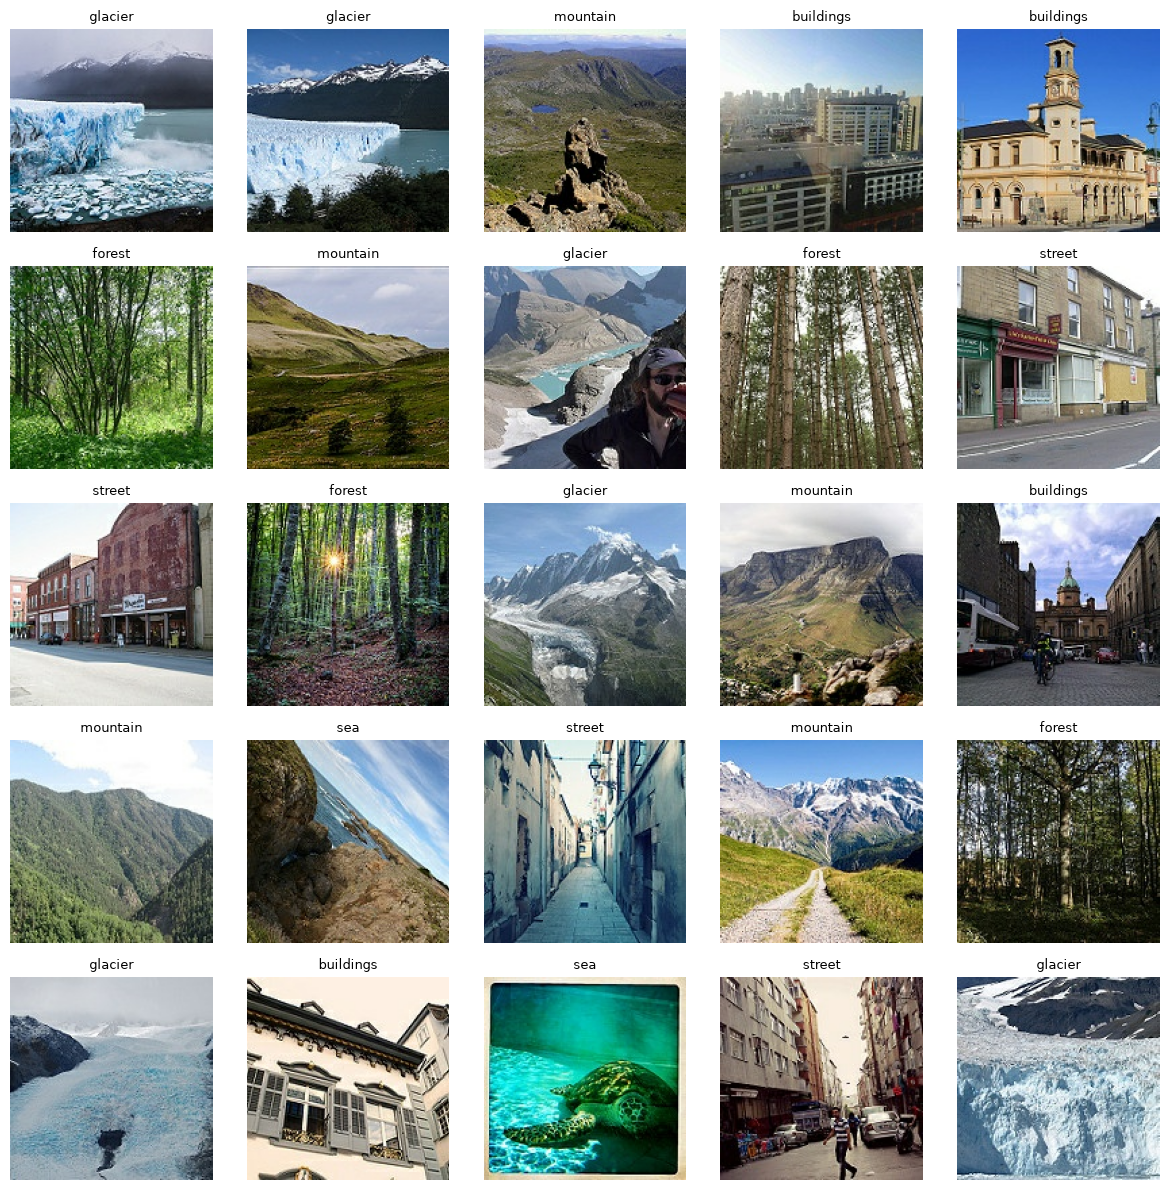

In [11]:
# Show 25 sample images

plt.figure(figsize=(12, 12))

images, labels = next(iter(train_ds))

for i in range(25):
    ax = plt.subplot(5, 5, i + 1)

    # Convert MobileNetV2 [-1, 1] values back to [0, 1] for display
    img = (images[i].numpy() + 1.0) / 2.0

    plt.imshow(img)
    plt.title(class_names[int(labels[i])], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()


### Learning Rate Schedulers

In [12]:
# Must be input as callback in train_and_test(....   , callbacks=[reduce_lr] )

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',    # Quantity to be monitored.
    factor=0.5,            # Factor by which the learning rate will be reduced.
                           # new_lr = lr * factor
    patience=3,            # Number of epochs with no improvement
                           # after which learning rate will be reduced.
    min_delta=1e-4,        # Threshold for measuring the new optimum,
                           # to only focus on significant changes.
    cooldown=0,            # Number of epochs to wait before resuming
                           # normal operation after lr has been reduced.
    min_lr=1e-7,           # Lower bound on the learning rate.
    verbose=1,             # 0: quiet, 1: update messages.
)

### Prelude: Baseline Model

`MobileNetV2` is a lightweight CNN pretrained on the ImageNet dataset. We will use it as a source of high-quality visual features rather than training a convolutional network from scratch.

See the **Appendix** for additional information about `MobileNetV2`.

The baseline model defined below uses `MobileNetV2` as a frozen **feature extractor**. With `include_top=False` and built-in **Global Average Pooling**, the backbone produces a 1280-dimensional feature vector for each image.

The images have already been processed using `mobilenet_v2.preprocess_input`, which scales the pixel values to the range expected by the pretrained MobileNetV2 weights.

> **NOTE:** The standard MobileNetV2 ImageNet weights are associated with 224×224 images. We use 150×150 images to reduce training time. This is valid because, with `include_top=False`, the convolutional backbone can operate on different input image sizes.
>
> Keras may therefore issue a warning such as:
>
> `UserWarning: input_shape is undefined or non-square, ...`
>
> You may safely ignore this warning for this assignment.


In [13]:
# ALWAYS construct a new instance to avoid sharing layers across models.

def make_base_model_pooled(trainable=False):
    base = mobilenet_v2.MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=INPUT_SHAPE,
        pooling="avg",
    )
    base.trainable = trainable
    return base


base = make_base_model_pooled()

print("Some statistics on the model:")
print("Total Keras layers:", len(base.layers))

# Count unique inverted-residual blocks by their prefix 'block_<n>'
block_ids = sorted({
    int(layer.name.split("_")[1])
    for layer in base.layers
    if layer.name.startswith("block_")
})
print("Conv Block IDs:", block_ids, "(count:", len(block_ids), ")")

# Check whether the final Conv_1 stage exists
has_conv1 = any(
    layer.name.startswith("Conv_1")
    for layer in base.layers
)

print("Has Conv_1 stage:", has_conv1)
print("Model Output Shape:", base.output_shape)

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(


Some statistics on the model:
Total Keras layers: 155
Conv Block IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16] (count: 16 )
Has Conv_1 stage: True
Model Output Shape: (None, 1280)


In [14]:
# Ha, this is very long!

# base.summary()

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



Model Baseline

Epoch 1/500


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1790700337.800498    3058 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


347/351 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8595 - loss: 0.3863

E0000 00:00:1790700345.121252    3058 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8599 - loss: 0.3854

E0000 00:00:1790700352.648467    3055 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


351/351 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - accuracy: 0.8599 - loss: 0.3854 - val_accuracy: 0.8891 - val_loss: 0.2995
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9102 - loss: 0.2485 - val_accuracy: 0.8994 - val_loss: 0.2758
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9209 - loss: 0.2142 - val_accuracy: 0.8919 - val_loss: 0.2996
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9292 - loss: 0.1939 - val_accuracy: 0.9012 - val_loss: 0.2792
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9349 - loss: 0.1765 - val_accuracy: 0.8791 - val_loss: 0.3571
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9381 - loss: 0.1655 - val_accuracy: 0.8973 - val_loss: 0.3018
Epoch 7/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9416 - loss: 0.1542 - val_accuracy: 0.8916 - val_loss: 0.3050
Epoch 8/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9458 - loss: 0.1445 - val_accurac

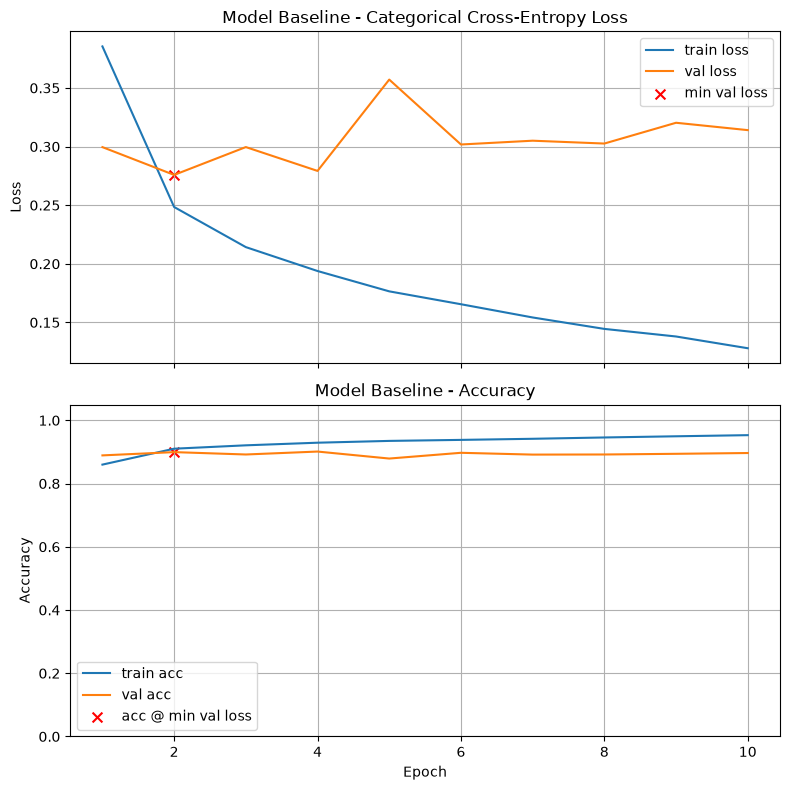

Final Training Loss:            0.1280
Final Training Accuracy:        0.9531
Final Validation Loss:          0.3140
Final Validation Accuracy:      0.8966
Minimum Validation Loss:        0.2758 (Epoch 2)
Validation Accuracy @ Min Loss: 0.8994


E0000 00:00:1790700387.590896    3057 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Test Loss: 0.2627
Test Accuracy: 0.9023

Validation-Test Gap (accuracy): 0.002904

Execution Time: 00:00:56


In [15]:
# Construct a fresh frozen MobileNetV2 backbone

base_model = make_base_model_pooled()

model_baseline = models.Sequential([
    base_model,
    Dense(num_classes, activation='softmax')  # use your Intel num_classes (6)
])

train_and_test(model_baseline, title="Model Baseline")

### Problem 1 — Frozen MobileNetV2 (Feature Extractor): Redesign the Head

**Goal.** Keep the MobileNetV2 backbone **frozen** and try to improve accuracy by modifying **only the classification head**.

**Setup.**

```python
base = make_base_model_pooled(
    trainable=False
)  # MobileNetV2(include_top=False, pooling="avg")
```

This backbone already applies **Global Average Pooling** and outputs a **1280-D feature vector** for each image.

Do **not** unfreeze any backbone layers, and do **not** add another pooling layer.

### To Do

1. **Ask an AI helper** (e.g., ChatGPT):

   *“What are some more complex classification heads that could improve this model on the Intel Image Classification Dataset, without unfreezing the MobileNetV2 backbone?”*

2. **Implement at least three different head designs.** These may be AI-suggested or inspired by techniques used in HW4.

3. **Experiment with hyperparameters** for the different designs, such as:

   * learning rate
   * `EarlyStopping` settings
   * Dropout and/or L2 regularization
   * `ReduceLROnPlateau` on or off

4. **Train and compare** the three head designs using a reduced value of `DATA_FRACTION`.

   Use these runs to compare architectures and training behavior and to narrow down a reasonable final configuration.

5. **Select one configuration**, set:

```python
DATA_FRACTION = 1.0
```

and rerun the notebook on the full dataset. Use this full-data run when answering the graded questions.

6. **Answer the graded questions.**

### Notes / Constraints

* With `pooling="avg"`, the backbone output has shape **(None, 1280)**, so **do not add `GlobalAveragePooling2D()`** to the head.
* `BatchNormalization` may be used within the classification head.
* Keep the entire MobileNetV2 backbone frozen for all experiments in this problem.
* Construct a **new backbone/model for each experiment** so that experiments do not inherit weights from previous runs.
* Small shifts in relative performance between reduced-data experiments and the full dataset are expected.



#### Design 1: Dense Layer (256 relu)

##### Baseline

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 1. Dense 256

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 26ms/step - accuracy: 0.8744 - loss: 0.3529 - val_accuracy: 0.8927 - val_loss: 0.3036
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9183 - loss: 0.2204 - val_accuracy: 0.8966 - val_loss: 0.2911
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9324 - loss: 0.1741 - val_accuracy: 0.8969 - val_loss: 0.3079
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9426 - loss: 0.1485 - val_accuracy: 0.8934 - val_loss: 0.2986
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9545 - loss: 0.1166 - val_accuracy: 0.8973 - val_loss: 0.2981
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9683 - loss: 0.0873 - val_accuracy: 0.8941 - val_loss: 0.3479
Epoch 7/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9752 - loss: 0.0707 - val_accuracy: 0.9055 - val_loss: 0.3274
Epoch 8/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy

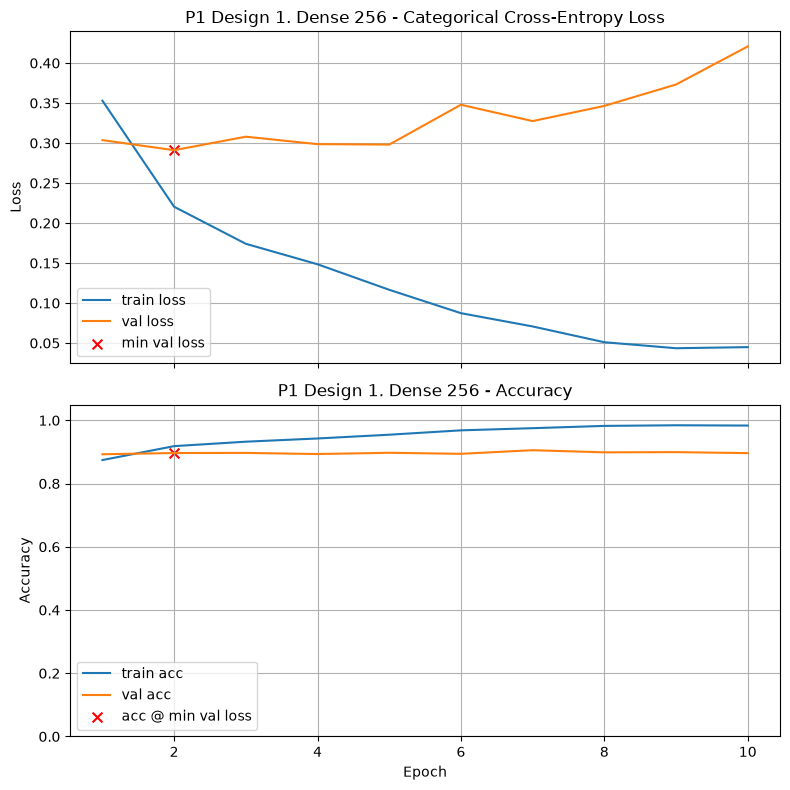

Final Training Loss:            0.0449
Final Training Accuracy:        0.9834
Final Validation Loss:          0.4208
Final Validation Accuracy:      0.8962
Minimum Validation Loss:        0.2911 (Epoch 2)
Validation Accuracy @ Min Loss: 0.8966

Test Loss: 0.2591
Test Accuracy: 0.8973

Validation-Test Gap (accuracy): 0.000757

Execution Time: 00:00:50


In [16]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d1_baseline = models.Sequential([
    base_model,
    Dense(256, activation='relu'),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d1_baseline, title="P1 Design 1. Dense 256")

##### Dropout 0.5

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 1. Dense 256 with Dropout

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 26ms/step - accuracy: 0.8468 - loss: 0.4276 - val_accuracy: 0.9030 - val_loss: 0.2824
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8914 - loss: 0.2935 - val_accuracy: 0.9094 - val_loss: 0.2786
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9082 - loss: 0.2547 - val_accuracy: 0.9083 - val_loss: 0.2700
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9161 - loss: 0.2253 - val_accuracy: 0.9051 - val_loss: 0.2669
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9169 - loss: 0.2209 - val_accuracy: 0.9119 - val_loss: 0.2572
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9239 - loss: 0.2064 - val_accuracy: 0.9080 - val_loss: 0.2723
Epoch 7/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9262 - loss: 0.1889 - val_accuracy: 0.9119 - val_loss: 0.2696
Epoch 8/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/st

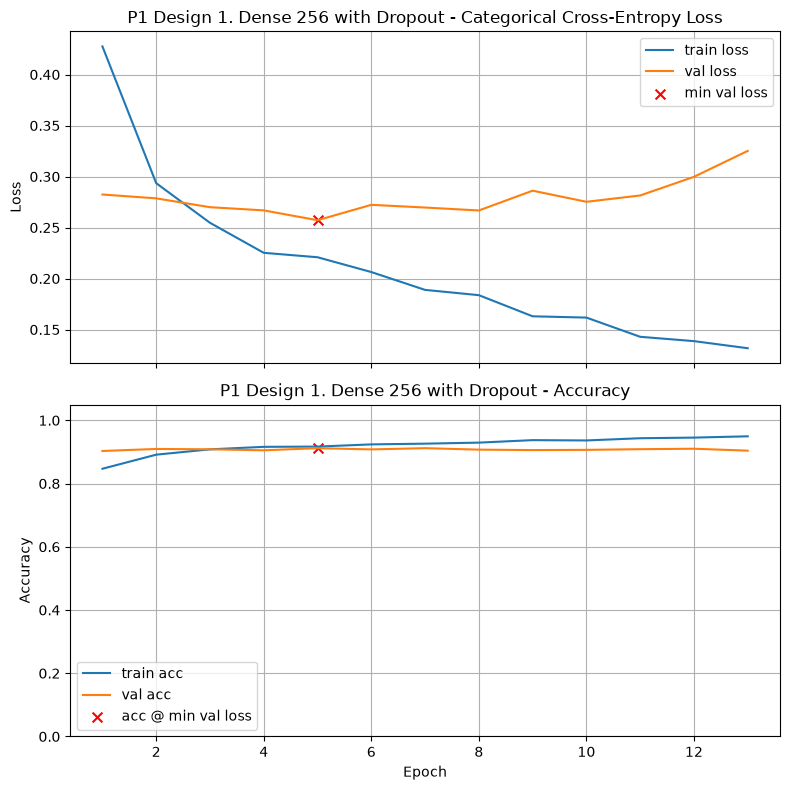

Final Training Loss:            0.1317
Final Training Accuracy:        0.9494
Final Validation Loss:          0.3252
Final Validation Accuracy:      0.9041
Minimum Validation Loss:        0.2572 (Epoch 5)
Validation Accuracy @ Min Loss: 0.9119

Test Loss: 0.2394
Test Accuracy: 0.9083

Validation-Test Gap (accuracy): 0.003578

Execution Time: 00:00:59


In [17]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d1_dropout = models.Sequential([
    base_model,
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d1_dropout, title="P1 Design 1. Dense 256 with Dropout")

##### Decreased lr 1e-4

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 1. Dense 256 with lr 1e-4

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.7465 - loss: 0.7058 - val_accuracy: 0.8894 - val_loss: 0.3186
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8706 - loss: 0.3586 - val_accuracy: 0.8976 - val_loss: 0.2905
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8890 - loss: 0.3093 - val_accuracy: 0.9009 - val_loss: 0.2772
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9033 - loss: 0.2705 - val_accuracy: 0.8991 - val_loss: 0.2728
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9097 - loss: 0.2490 - val_accuracy: 0.9041 - val_loss: 0.2690
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9153 - loss: 0.2341 - val_accuracy: 0.9041 - val_loss: 0.2620
Epoch 7/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9216 - loss: 0.2196 - val_accuracy: 0.9073 - val_loss: 0.2604
Epoch 8/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/st

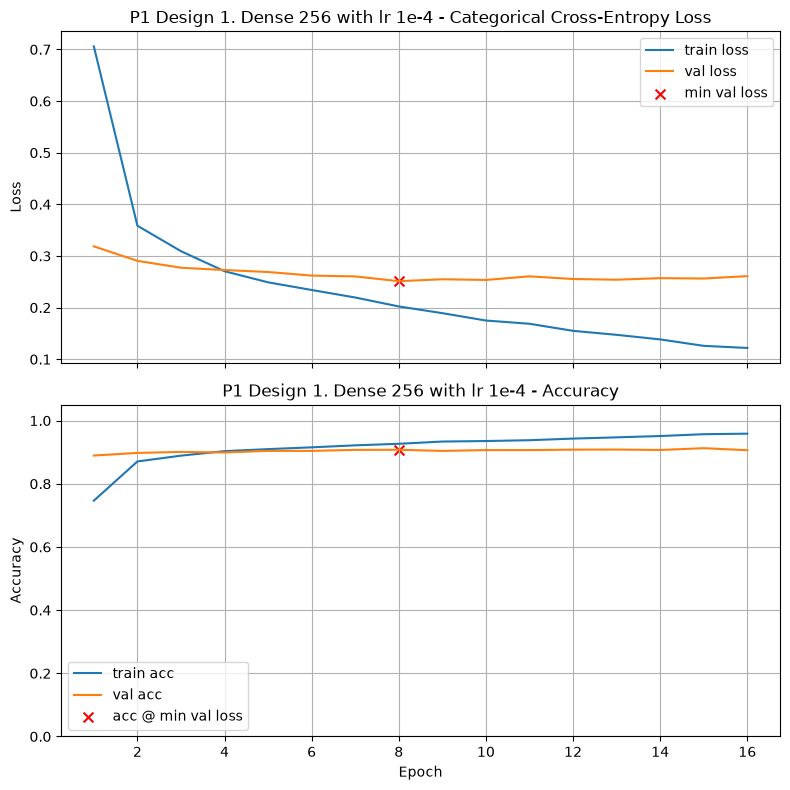

Final Training Loss:            0.1219
Final Training Accuracy:        0.9586
Final Validation Loss:          0.2610
Final Validation Accuracy:      0.9062
Minimum Validation Loss:        0.2512 (Epoch 8)
Validation Accuracy @ Min Loss: 0.9076

Test Loss: 0.2300
Test Accuracy: 0.9093

Validation-Test Gap (accuracy): 0.001701

Execution Time: 00:01:08


In [18]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d1_lr = models.Sequential([
    base_model,
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d1_lr, title="P1 Design 1. Dense 256 with lr 1e-4", lr_schedule=1e-4)

##### ReduceLROnPlateau

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 1. Dense 256 with ReduceLROnPlateau

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.8759 - loss: 0.3494 - val_accuracy: 0.9048 - val_loss: 0.2731 - learning_rate: 0.0010
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9146 - loss: 0.2228 - val_accuracy: 0.9005 - val_loss: 0.2820 - learning_rate: 0.0010
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9295 - loss: 0.1807 - val_accuracy: 0.9091 - val_loss: 0.2682 - learning_rate: 0.0010
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9409 - loss: 0.1481 - val_accuracy: 0.9076 - val_loss: 0.2723 - learning_rate: 0.0010
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9591 - loss: 0.1128 - val_accuracy: 0.8966 - val_loss: 0.3072 - learning_rate: 0.0010
Epoch 6/500
350/351 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9647 - loss: 0.0935
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
351/351 ━━━━━━━━━━

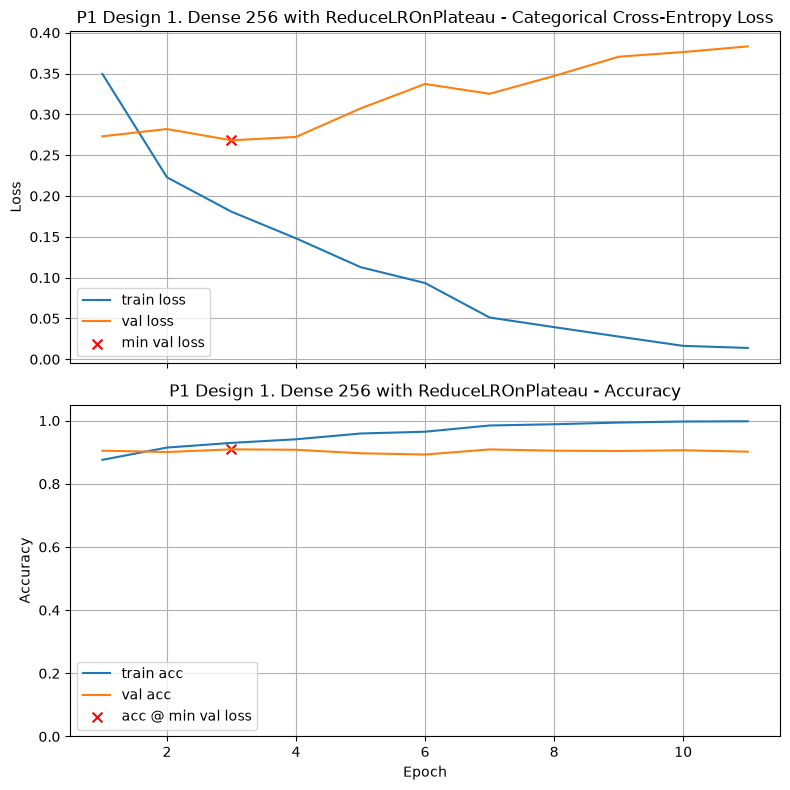

Final Training Loss:            0.0139
Final Training Accuracy:        0.9979
Final Validation Loss:          0.3832
Final Validation Accuracy:      0.9016
Minimum Validation Loss:        0.2682 (Epoch 3)
Validation Accuracy @ Min Loss: 0.9091

Test Loss: 0.2382
Test Accuracy: 0.9067

Validation-Test Gap (accuracy): 0.002392

Execution Time: 00:00:50


In [19]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d1_reduce_lr = models.Sequential([
    base_model,
    Dense(256, activation='relu'),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d1_reduce_lr, title="P1 Design 1. Dense 256 with ReduceLROnPlateau", callbacks=[reduce_lr])

##### Combination

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 1. Dense 256 with Dropout and ReduceLROnPlateau

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.8525 - loss: 0.4277 - val_accuracy: 0.8845 - val_loss: 0.3195 - learning_rate: 0.0010
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8924 - loss: 0.2947 - val_accuracy: 0.9048 - val_loss: 0.2689 - learning_rate: 0.0010
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9052 - loss: 0.2592 - val_accuracy: 0.9037 - val_loss: 0.2622 - learning_rate: 0.0010
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9103 - loss: 0.2376 - val_accuracy: 0.9044 - val_loss: 0.2615 - learning_rate: 0.0010
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9180 - loss: 0.2198 - val_accuracy: 0.9062 - val_loss: 0.2596 - learning_rate: 0.0010
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9245 - loss: 0.2007 - val_accuracy: 0.9066 - val_loss: 0.2629 - learning_rate: 0.0010
Epoch 7/500
351

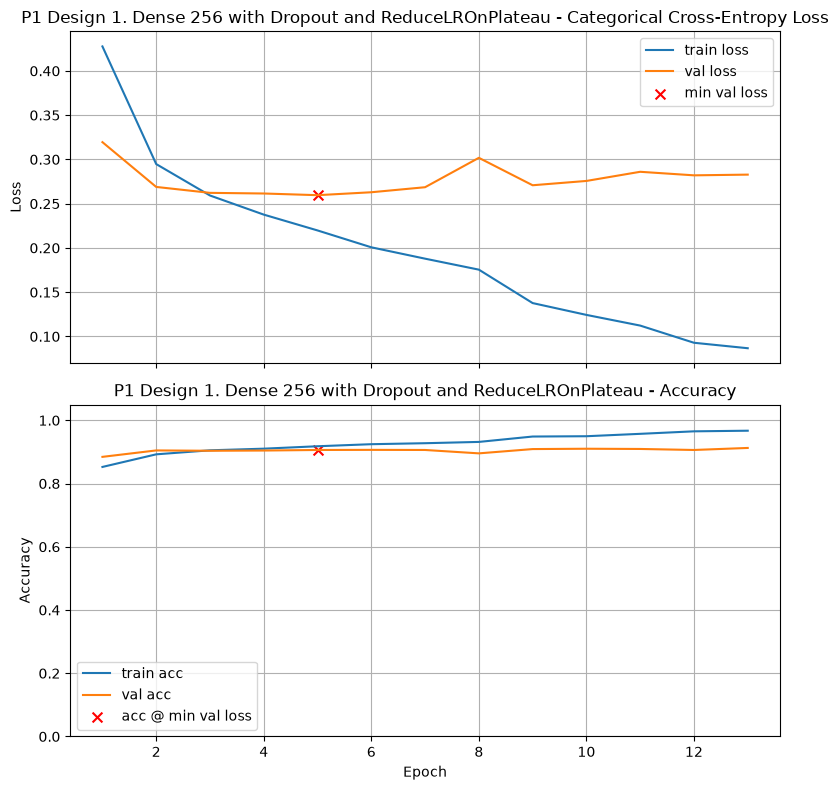

Final Training Loss:            0.0867
Final Training Accuracy:        0.9671
Final Validation Loss:          0.2828
Final Validation Accuracy:      0.9126
Minimum Validation Loss:        0.2596 (Epoch 5)
Validation Accuracy @ Min Loss: 0.9062

Test Loss: 0.2454
Test Accuracy: 0.9097

Validation-Test Gap (accuracy): 0.003461

Execution Time: 00:00:59


In [20]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d1_reduce_final = models.Sequential([
    base_model,
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d1_reduce_final, title="P1 Design 1. Dense 256 with Dropout and ReduceLROnPlateau", callbacks=[reduce_lr])

#### Design 2: Dense -> Dropout -> Dense -> Dropout

##### Baseline

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 2. Dense-Dropout-Dense-Dropout

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.8331 - loss: 0.4646 - val_accuracy: 0.8869 - val_loss: 0.3108
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8851 - loss: 0.3254 - val_accuracy: 0.9019 - val_loss: 0.2771
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8931 - loss: 0.2948 - val_accuracy: 0.8976 - val_loss: 0.2972
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9073 - loss: 0.2572 - val_accuracy: 0.8966 - val_loss: 0.2676
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9106 - loss: 0.2427 - val_accuracy: 0.8909 - val_loss: 0.3028
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9174 - loss: 0.2264 - val_accuracy: 0.9062 - val_loss: 0.2752
Epoch 7/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9181 - loss: 0.2208 - val_accuracy: 0.9066 - val_loss: 0.2702
Epoch 8/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11

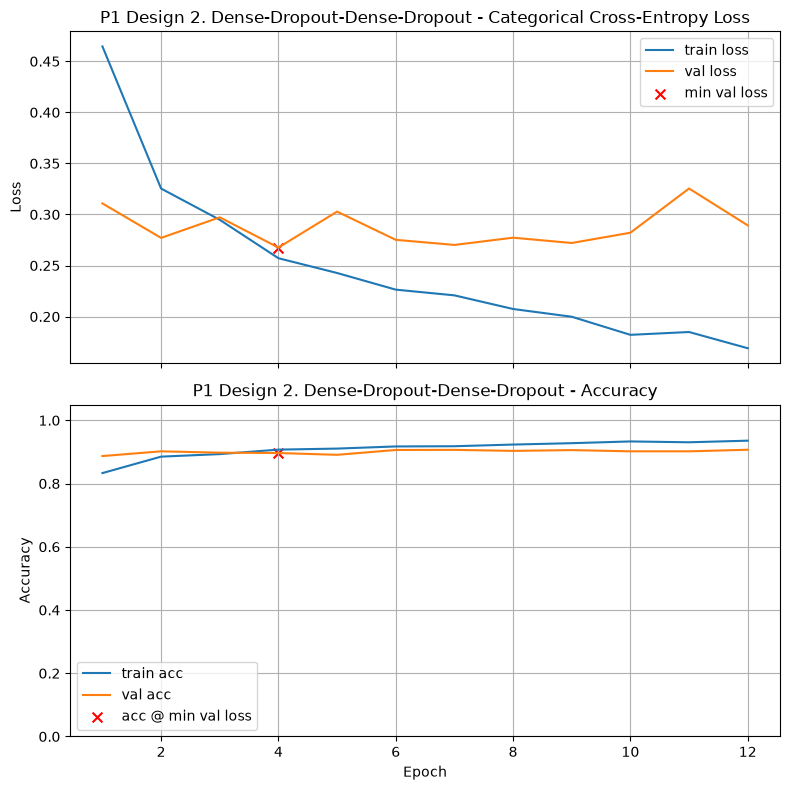

Final Training Loss:            0.1690
Final Training Accuracy:        0.9356
Final Validation Loss:          0.2893
Final Validation Accuracy:      0.9069
Minimum Validation Loss:        0.2676 (Epoch 4)
Validation Accuracy @ Min Loss: 0.8966

Test Loss: 0.2487
Test Accuracy: 0.9060

Validation-Test Gap (accuracy): 0.009424

Execution Time: 00:00:59


In [21]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d2_baseline = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d2_baseline, title="P1 Design 2. Dense-Dropout-Dense-Dropout")

##### Decreased lr 1e-4

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 2. Dense-Dropout-Dense-Dropout lr 1e-4

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 14s 27ms/step - accuracy: 0.7383 - loss: 0.7092 - val_accuracy: 0.8916 - val_loss: 0.3129
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8581 - loss: 0.3855 - val_accuracy: 0.8998 - val_loss: 0.2822
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8808 - loss: 0.3263 - val_accuracy: 0.9016 - val_loss: 0.2752
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8941 - loss: 0.2924 - val_accuracy: 0.9034 - val_loss: 0.2641
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9040 - loss: 0.2667 - val_accuracy: 0.9098 - val_loss: 0.2608
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9110 - loss: 0.2502 - val_accuracy: 0.9091 - val_loss: 0.2599
Epoch 7/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9184 - loss: 0.2272 - val_accuracy: 0.9112 - val_loss: 0.2575
Epoch 8/500
351/351 ━━━━━━━━━━━━━━━━━━

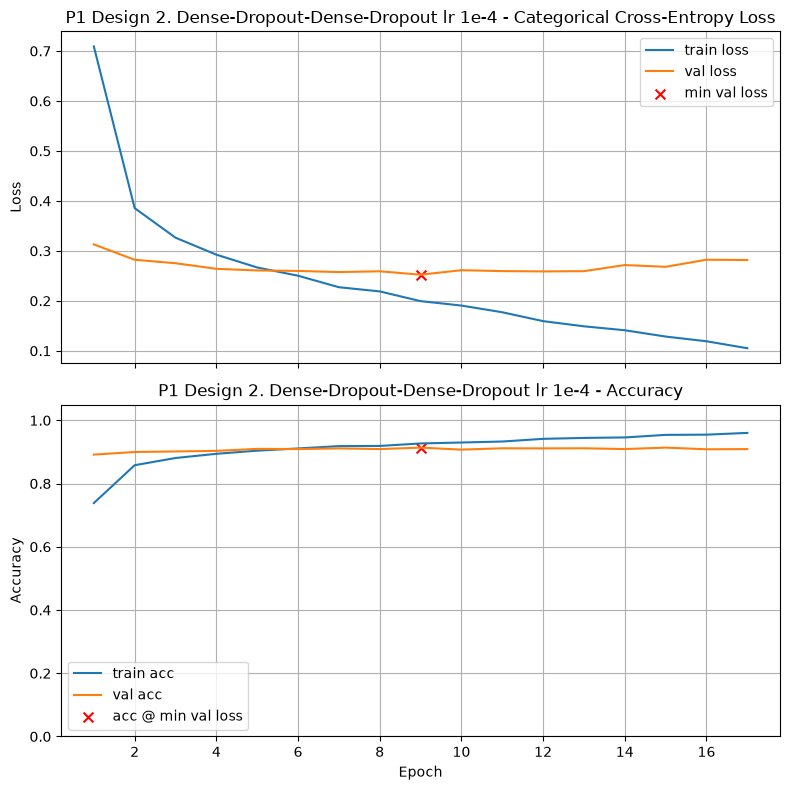

Final Training Loss:            0.1051
Final Training Accuracy:        0.9602
Final Validation Loss:          0.2817
Final Validation Accuracy:      0.9091
Minimum Validation Loss:        0.2523 (Epoch 9)
Validation Accuracy @ Min Loss: 0.9137

Test Loss: 0.2230
Test Accuracy: 0.9140

Validation-Test Gap (accuracy): 0.000305

Execution Time: 00:01:14


In [22]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d2_lr_1e4 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d2_lr_1e4, title="P1 Design 2. Dense-Dropout-Dense-Dropout lr 1e-4", lr_schedule=1e-4)

##### ReduceLROnPlateau

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 2. Dense-Dropout-Dense-Dropout ReuceLROnPlateau

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 14s 27ms/step - accuracy: 0.8272 - loss: 0.4843 - val_accuracy: 0.8962 - val_loss: 0.2939 - learning_rate: 0.0010
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8809 - loss: 0.3227 - val_accuracy: 0.8934 - val_loss: 0.2955 - learning_rate: 0.0010
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8973 - loss: 0.2859 - val_accuracy: 0.9080 - val_loss: 0.2619 - learning_rate: 0.0010
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9069 - loss: 0.2598 - val_accuracy: 0.9044 - val_loss: 0.2648 - learning_rate: 0.0010
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9092 - loss: 0.2478 - val_accuracy: 0.9066 - val_loss: 0.2667 - learning_rate: 0.0010
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9162 - loss: 0.2312
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
351/35

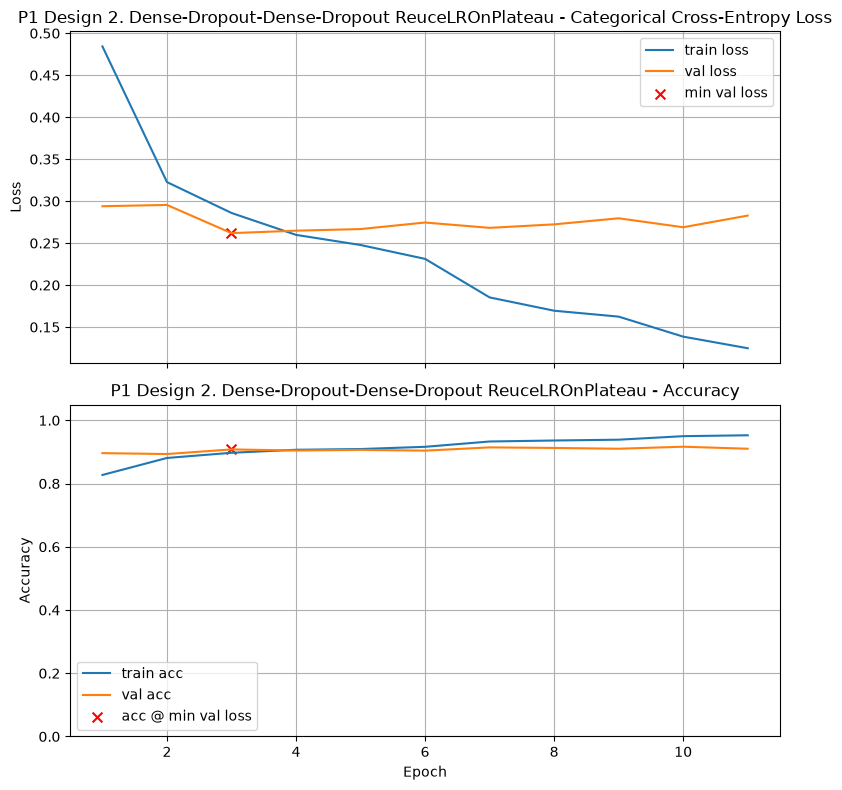

Final Training Loss:            0.1248
Final Training Accuracy:        0.9527
Final Validation Loss:          0.2828
Final Validation Accuracy:      0.9101
Minimum Validation Loss:        0.2619 (Epoch 3)
Validation Accuracy @ Min Loss: 0.9080

Test Loss: 0.2504
Test Accuracy: 0.9063

Validation-Test Gap (accuracy): 0.001655

Execution Time: 00:00:53


In [23]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d2_reduce_lr = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d2_reduce_lr, title="P1 Design 2. Dense-Dropout-Dense-Dropout ReuceLROnPlateau", callbacks=[reduce_lr])

#### Design 3: Dense-Dropout-Dense-Dropout with Regularization and Batch Normalization

##### Baseline

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 17s 31ms/step - accuracy: 0.8500 - loss: 0.5572 - val_accuracy: 0.8959 - val_loss: 0.4079
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8926 - loss: 0.4160 - val_accuracy: 0.9048 - val_loss: 0.3818
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8996 - loss: 0.3838 - val_accuracy: 0.9076 - val_loss: 0.3813
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9099 - loss: 0.3600 - val_accuracy: 0.9105 - val_loss: 0.3762
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9148 - loss: 0.3415 - val_accuracy: 0.9005 - val_loss: 0.4116
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9194 - loss: 0.3310 - val_accuracy: 0.9034 - val_loss: 0.3926
Epoch 7/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9202 - loss: 0.3267 - val_accuracy: 0.9083 - val_loss: 0.3894
Epoch 8/500
351/351 

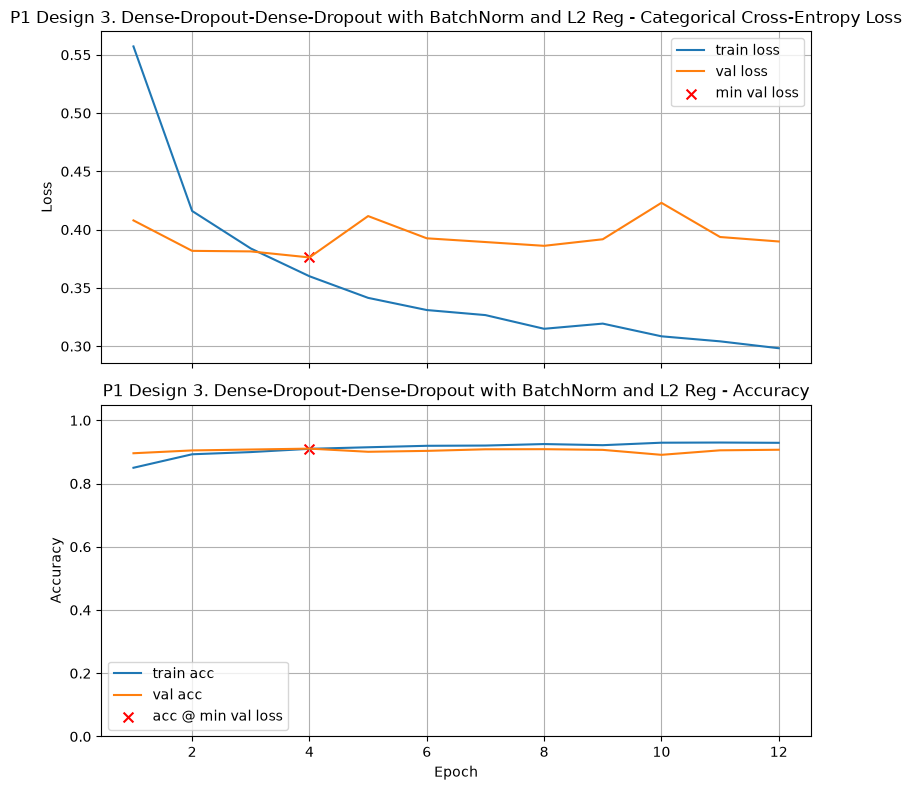

Final Training Loss:            0.2983
Final Training Accuracy:        0.9289
Final Validation Loss:          0.3898
Final Validation Accuracy:      0.9069
Minimum Validation Loss:        0.3762 (Epoch 4)
Validation Accuracy @ Min Loss: 0.9105

Test Loss: 0.3540
Test Accuracy: 0.9060

Validation-Test Gap (accuracy): 0.004485

Execution Time: 00:01:02


In [24]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d3_baseline = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d3_baseline, title="P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg")

##### Decreased regularization 1e-3

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg 1e-3

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.8470 - loss: 1.4448 - val_accuracy: 0.9030 - val_loss: 1.1803
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8916 - loss: 1.0838 - val_accuracy: 0.8845 - val_loss: 0.9992
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8947 - loss: 0.8727 - val_accuracy: 0.9009 - val_loss: 0.7894
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9000 - loss: 0.7206 - val_accuracy: 0.8959 - val_loss: 0.7004
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9054 - loss: 0.6248 - val_accuracy: 0.8891 - val_loss: 0.6266
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9050 - loss: 0.5653 - val_accuracy: 0.8869 - val_loss: 0.6088
Epoch 7/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9037 - loss: 0.5337 - val_accuracy: 0.9058 - val_loss: 0.5223
Epoch 8/500
351

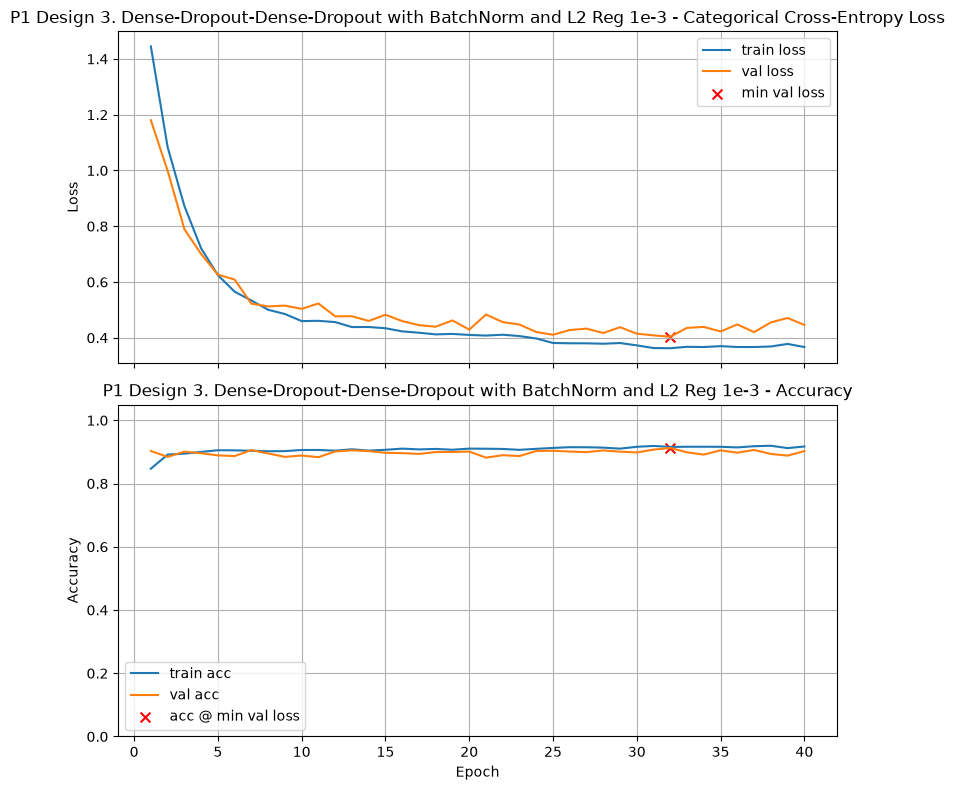

Final Training Loss:            0.3669
Final Training Accuracy:        0.9172
Final Validation Loss:          0.4461
Final Validation Accuracy:      0.9026
Minimum Validation Loss:        0.4038 (Epoch 32)
Validation Accuracy @ Min Loss: 0.9126

Test Loss: 0.3899
Test Accuracy: 0.9020

Validation-Test Gap (accuracy): 0.010625

Execution Time: 00:02:41


In [25]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d3_decreased_reg = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d3_decreased_reg, title="P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg 1e-3")

##### ReduceLROnPlateau

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg and ReduceLR

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.8466 - loss: 0.5562 - val_accuracy: 0.8823 - val_loss: 0.4399 - learning_rate: 0.0010
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8862 - loss: 0.4288 - val_accuracy: 0.9016 - val_loss: 0.3960 - learning_rate: 0.0010
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9054 - loss: 0.3795 - val_accuracy: 0.9076 - val_loss: 0.3847 - learning_rate: 0.0010
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9102 - loss: 0.3556 - val_accuracy: 0.8973 - val_loss: 0.3937 - learning_rate: 0.0010
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9195 - loss: 0.3316 - val_accuracy: 0.8880 - val_loss: 0.4066 - learning_rate: 0.0010
Epoch 6/500
349/351 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9167 - loss: 0.3365
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.00050

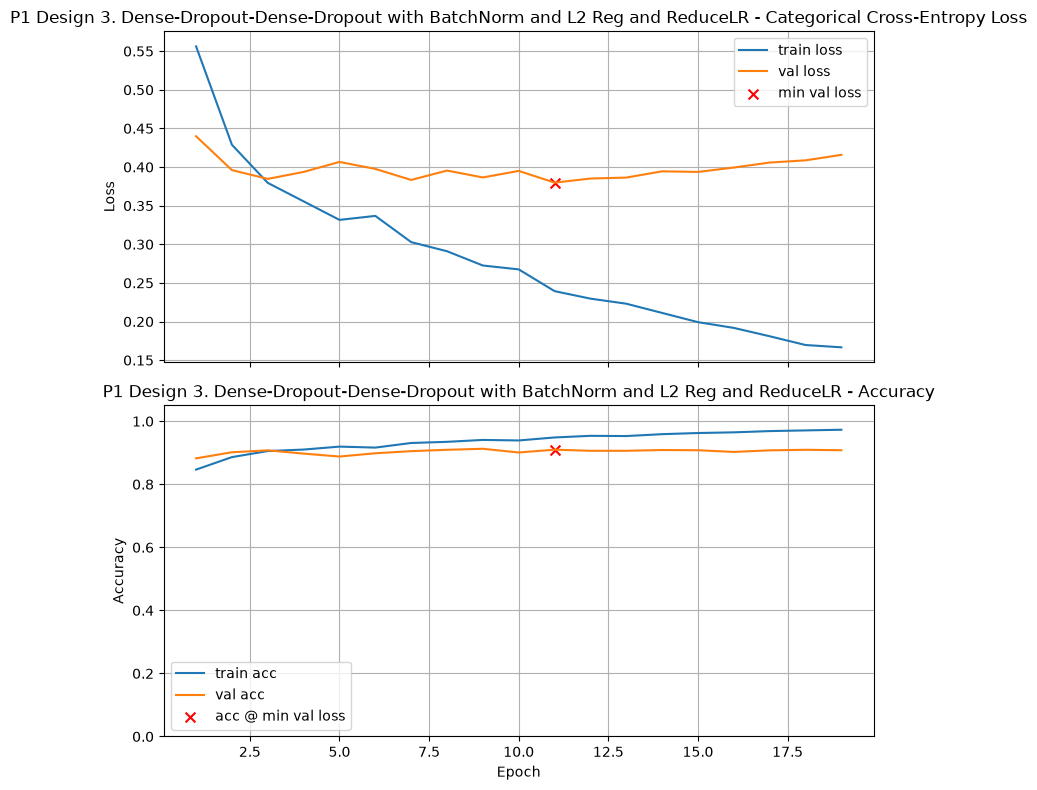

Final Training Loss:            0.1667
Final Training Accuracy:        0.9730
Final Validation Loss:          0.4158
Final Validation Accuracy:      0.9080
Minimum Validation Loss:        0.3798 (Epoch 11)
Validation Accuracy @ Min Loss: 0.9098

Test Loss: 0.3443
Test Accuracy: 0.9120

Validation-Test Gap (accuracy): 0.002228

Execution Time: 00:01:26


In [26]:
base_model = make_base_model_pooled(trainable=False)

model_p1_d3_reduce_lr = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p1_d3_reduce_lr, title="P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg and ReduceLR", callbacks=[reduce_lr])

# Graded Questions

The reflection question is worth 5 points, and the validation accuracy question is worth 15 points. 

**Reflection Question:**

Which head architecture worked best for you, and what does that suggest about the role of head design and hyperparameters when the backbone is frozen?

**Instructions:**

- Write a single paragraph (3–5 sentences).
- Identify the head architecture and experiment that performed best.
- Briefly compare it with the other experiments, referring to specific design choices (e.g., dense layers, dropout) and hyperparameters (e.g., learning rate, ReduceLROnPlateau).
- Explain which of these differences you think were most important, based on your observed training and validation results.
- Conclude with what your experiments suggest about designing classification heads when the backbone is frozen.


In [27]:
print_results()

P1 Design 2. Dense-Dropout-Dense-Dropout lr 1e-4	0.9137	9
P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg 1e-3	0.9126	32
P1 Design 1. Dense 256 with Dropout     	0.9119	5
P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg	0.9105	4
P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg and ReduceLR	0.9098	11
P1 Design 1. Dense 256 with ReduceLROnPlateau	0.9091	3
P1 Design 2. Dense-Dropout-Dense-Dropout ReuceLROnPlateau	0.9080	3
P1 Design 1. Dense 256 with lr 1e-4     	0.9076	8
P1 Design 1. Dense 256 with Dropout and ReduceLROnPlateau	0.9062	5
Model Baseline                          	0.8994	2
P1 Design 1. Dense 256                  	0.8966	2
P1 Design 2. Dense-Dropout-Dense-Dropout	0.8966	4


I experimented with three architectures-the first architecture used a simple model using a single Dense 256 layer and I tested out hyperparameters such as learning rate, ReduceLROnPlateau, and Dropout; the second archtiecture consists of 512 Dense Layer, Dropout, 256 Dense Layer, Dropout; the third architecture consists of 512 Dense Layer (L2 Regularized), BatchNormalization, Dropout, 256 Dense Layer (L2 Regularized), BatchNormalization, Dropout.

We can see in the results above that the second architecture performed the best with 0.9137 validation accuracy, but it was closely followed by the 3rd and 1st architectures with 0.9126 and 0.9119 respectively. All three architectures had performance within 0.018, which can be attributed to noise. Overall these heads provide a modest lift over the baseline model which had a 0.8994 validation accuracy.

Based on these results, we can see that dropout and learning rate had the most significant impact on the validation accuracy. We can conclude that there was no benefit in more complex head architectures across my experiments over a simpler model as long as the optimal learning rate and dropout was used. This shows that with a strong frozen backbone, a simpler head architecture can be used to modestly boost model performance on a specific domain. To further research, more granular hyperparamter tuning could be performed on the complex architectures to test more optimal parameter selections.

**Validation Accuracy here (15 pts):**

In [49]:
# Set a1 to the validation accuracy found by your best model for this problem. 

a1 = 0.9137             # Replace 0.0 with your answer

In [50]:
# Graded Answer
# DO NOT change this cell in any way and do not make any other assignments to variable a1a in this problem         

print(f'a1 = {a1:.4f}') 


a1 = 0.9137


## Problem Two — Training MobileNetV2 with the Backbone Unfrozen

**Goal.** Use the architecture of one of your best heads from Problem 1, but now make the MobileNetV2 backbone trainable so that the entire network can adapt to the Intel Image dataset.

**Setup.** Build a new MobileNetV2 backbone with `trainable=True`. It already applies Global Average Pooling and outputs a 1280-D vector, so do not add another pooling layer.

```python
base = make_base_model_pooled(
    trainable=True
)  # MobileNetV2(include_top=False, pooling="avg")
```

### To Do

1. **Design at least three experiments** with the MobileNetV2 backbone fully unfrozen. Use the architecture of one of your best heads from Problem 1 and vary one or more of the following:

   * **Learning rate**
   * **EarlyStopping** parameters
   * **Regularization:** Dropout and/or L2
   * **ReduceLROnPlateau:** on vs. off

2. **Run and compare** the three experiments using a reduced value of `DATA_FRACTION`, focusing on:

   * training stability,
   * convergence behavior,
   * and validation performance trends.

   Use these runs to **narrow down reasonable configurations**, not to identify a single “optimal” setting.

3. **Select one configuration**, set `DATA_FRACTION = 1.0`, rerun the notebook to train on the full dataset, and use this run when answering the graded questions.

### Notes

* Training a pretrained backbone generally requires a **much smaller learning rate** than training only a new classification head. Values such as \(1\times10^{-5}\) to \(3\times10^{-5}\) are reasonable starting points.
* Small changes in relative performance between experiments using a reduced dataset and the full dataset are expected.
* Each experiment should construct a **new model** so that experiments do not inherit weights from previous runs.



#### Experiment 1: Learning Rate Adjustments 

##### Baseline

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P2 Experiment 1 - LR Baseline

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 55s 83ms/step - accuracy: 0.8183 - loss: 0.5862 - val_accuracy: 0.5888 - val_loss: 3.7424 - learning_rate: 0.0010
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8850 - loss: 0.3668 - val_accuracy: 0.4058 - val_loss: 6.4583 - learning_rate: 0.0010
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8980 - loss: 0.3231 - val_accuracy: 0.4993 - val_loss: 3.5086 - learning_rate: 0.0010
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.9014 - loss: 0.3122 - val_accuracy: 0.4433 - val_loss: 5.3443 - learning_rate: 0.0010
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.9057 - loss: 0.3021 - val_accuracy: 0.6066 - val_loss: 3.1406 - learning_rate: 0.0010
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.9175 - loss: 0.2613 - val_accuracy: 0.5653 - val_loss: 2.7285 - learning_rate: 0.0010
Epoch 7/500
351/351 ━━━━━━━━━━━━━━━━━━

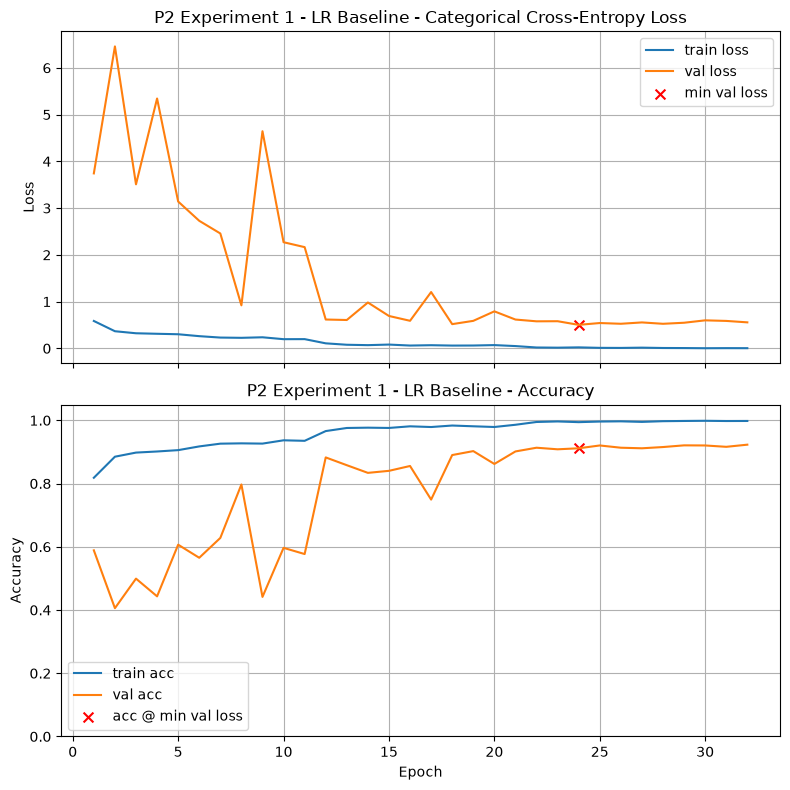

Final Training Loss:            0.0042
Final Training Accuracy:        0.9980
Final Validation Loss:          0.5566
Final Validation Accuracy:      0.9230
Minimum Validation Loss:        0.5032 (Epoch 24)
Validation Accuracy @ Min Loss: 0.9116

Test Loss: 0.5201
Test Accuracy: 0.9127

Validation-Test Gap (accuracy): 0.001112

Execution Time: 00:06:33


In [30]:
base_model = make_base_model_pooled(trainable=True)

model_p2_d1_lr_baseline = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p2_d1_lr_baseline, title="P2 Experiment 1 - LR Baseline", callbacks=[reduce_lr])

##### Decrease LR 1e-5

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P2 Experiment 1 - LR 1e-5

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 43s 67ms/step - accuracy: 0.3538 - loss: 1.6487 - val_accuracy: 0.7332 - val_loss: 0.8376 - learning_rate: 1.0000e-05
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.6800 - loss: 0.9101 - val_accuracy: 0.8427 - val_loss: 0.4359 - learning_rate: 1.0000e-05
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8033 - loss: 0.5814 - val_accuracy: 0.8695 - val_loss: 0.3557 - learning_rate: 1.0000e-05
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8472 - loss: 0.4572 - val_accuracy: 0.8780 - val_loss: 0.3390 - learning_rate: 1.0000e-05
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8676 - loss: 0.3906 - val_accuracy: 0.8944 - val_loss: 0.3073 - learning_rate: 1.0000e-05
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8815 - loss: 0.3430 - val_accuracy: 0.9051 - val_loss: 0.2802 - learning_rate: 1.0000e-05
Epoch 7/500
351/35

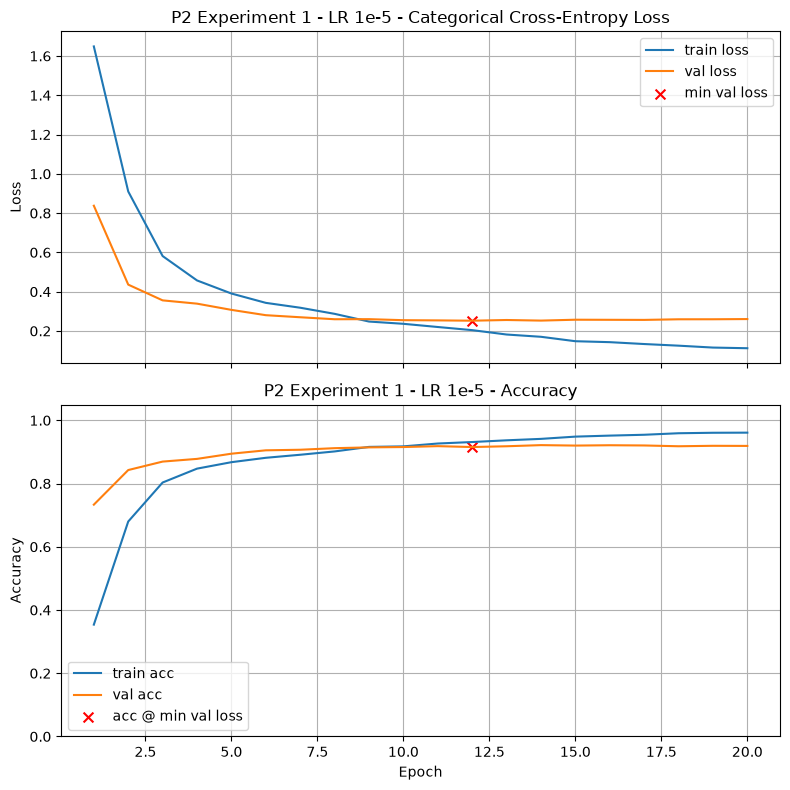

Final Training Loss:            0.1120
Final Training Accuracy:        0.9610
Final Validation Loss:          0.2605
Final Validation Accuracy:      0.9190
Minimum Validation Loss:        0.2522 (Epoch 12)
Validation Accuracy @ Min Loss: 0.9155

Test Loss: 0.2255
Test Accuracy: 0.9247

Validation-Test Gap (accuracy): 0.009189

Execution Time: 00:04:23


In [31]:
base_model = make_base_model_pooled(trainable=True)

model_p2_d1_lr_1e5 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p2_d1_lr_1e5, title="P2 Experiment 1 - LR 1e-5", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 2: Adjust Regularization

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P2 Experiment 1 - LR 1e-5 with L2Reg

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 45s 71ms/step - accuracy: 0.3853 - loss: 1.6679 - val_accuracy: 0.7771 - val_loss: 0.8449 - learning_rate: 1.0000e-05
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.6913 - loss: 0.9535 - val_accuracy: 0.8502 - val_loss: 0.5131 - learning_rate: 1.0000e-05
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8056 - loss: 0.6594 - val_accuracy: 0.8777 - val_loss: 0.4347 - learning_rate: 1.0000e-05
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8428 - loss: 0.5575 - val_accuracy: 0.8927 - val_loss: 0.4022 - learning_rate: 1.0000e-05
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8662 - loss: 0.4913 - val_accuracy: 0.8955 - val_loss: 0.3985 - learning_rate: 1.0000e-05
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8832 - loss: 0.4481 - val_accuracy: 0.9041 - val_loss: 0.3829 - learning_rate: 1.0000e-05
Epoch 7

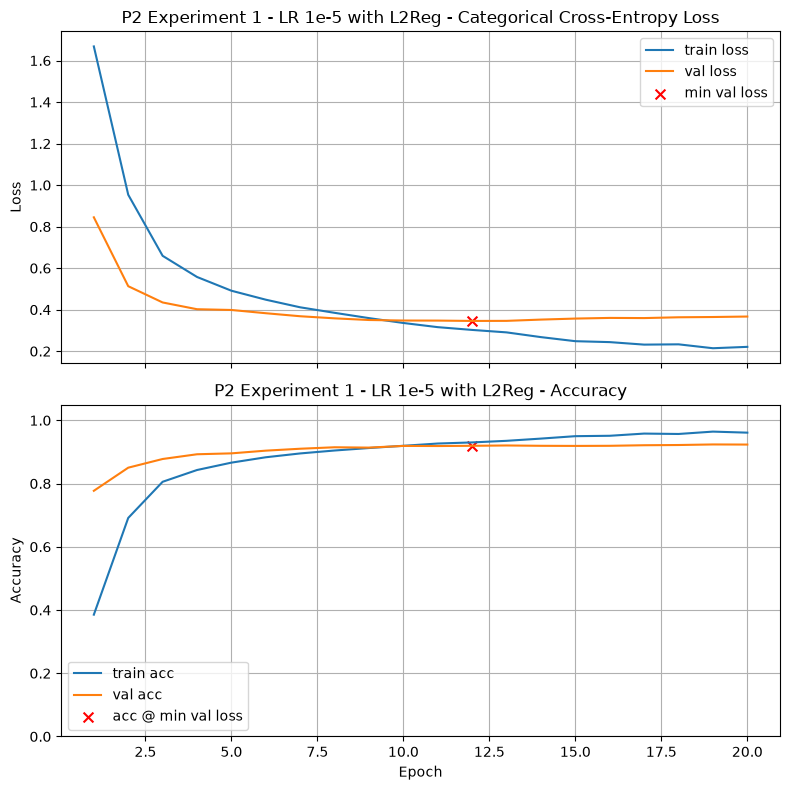

Final Training Loss:            0.2209
Final Training Accuracy:        0.9610
Final Validation Loss:          0.3670
Final Validation Accuracy:      0.9233
Minimum Validation Loss:        0.3458 (Epoch 12)
Validation Accuracy @ Min Loss: 0.9194

Test Loss: 0.3275
Test Accuracy: 0.9207

Validation-Test Gap (accuracy): 0.001266

Execution Time: 00:04:15


In [32]:
base_model = make_base_model_pooled(trainable=True)

model_p2_d2_l2 = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p2_d2_l2, title="P2 Experiment 1 - LR 1e-5 with L2Reg", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 3: Disable ReduceLROnPlateau

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P2 Experiment 1 - LR 1e-5, L2Reg, and no ReduceLROnPlateau

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 43s 69ms/step - accuracy: 0.3692 - loss: 1.7095 - val_accuracy: 0.7899 - val_loss: 0.8761
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.6926 - loss: 0.9698 - val_accuracy: 0.8545 - val_loss: 0.5034
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8039 - loss: 0.6661 - val_accuracy: 0.8641 - val_loss: 0.4564
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8473 - loss: 0.5406 - val_accuracy: 0.8770 - val_loss: 0.4329
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8675 - loss: 0.4845 - val_accuracy: 0.8980 - val_loss: 0.3999
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8840 - loss: 0.4480 - val_accuracy: 0.9069 - val_loss: 0.3773
Epoch 7/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8971 - loss: 0.4018 - val_accuracy: 0.9062 - val_loss: 0.3779
Epoch 8/500
351/351 ━━

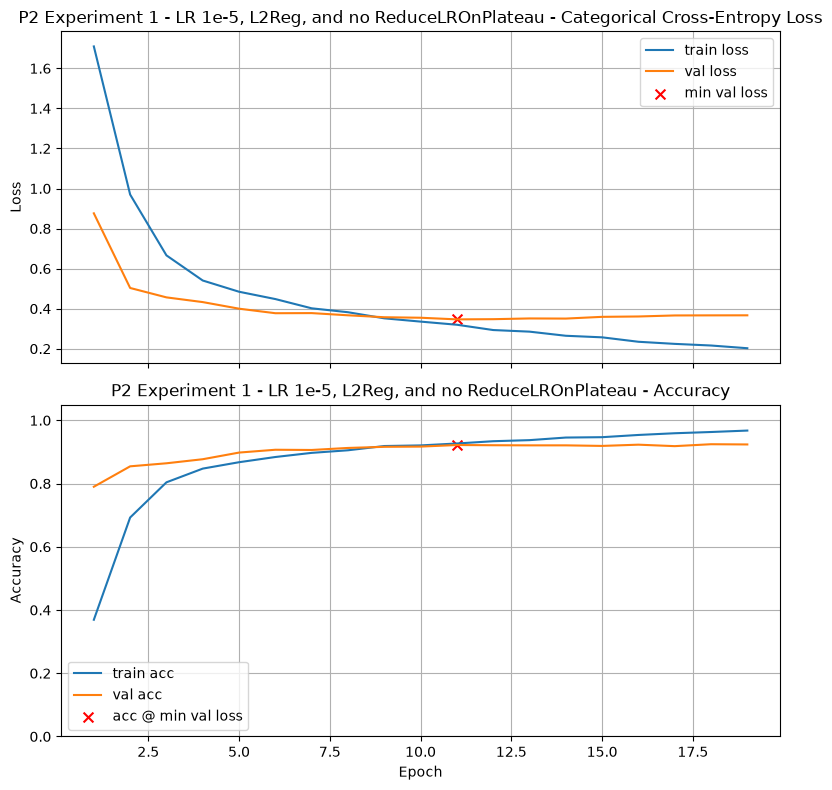

Final Training Loss:            0.2025
Final Training Accuracy:        0.9676
Final Validation Loss:          0.3668
Final Validation Accuracy:      0.9237
Minimum Validation Loss:        0.3466 (Epoch 11)
Validation Accuracy @ Min Loss: 0.9219

Test Loss: 0.3350
Test Accuracy: 0.9227

Validation-Test Gap (accuracy): 0.000769

Execution Time: 00:04:03


In [33]:
base_model = make_base_model_pooled(trainable=True)

model_p2_d2_l2_disable_reducelr = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p2_d2_l2_disable_reducelr, title="P2 Experiment 1 - LR 1e-5, L2Reg, and no ReduceLROnPlateau", lr_schedule=1e-5)

### Graded Questions

The reflection question is worth 5 points, and the validation accuracy question is worth 15 points. 

**Reflection Question:**

Which fully unfrozen configuration worked best for you, and what does that suggest about the role of head design and training hyperparameters when the MobileNetV2 backbone is trainable?

**Instructions:**

* Write a single paragraph (3–5 sentences).
* Explain your reasoning in choosing your three experimental designs.
* Identify the experiment that performed best.
* Briefly compare it with the other experiments, referring to both architectural choices (e.g., dense layers, dropout) and training hyperparameters (e.g., learning rate, `ReduceLROnPlateau`).
* Explain which differences you think were most important, based on the training and validation behavior you observed.
* Conclude with what your experiments suggest about training a model when the pretrained backbone is fully unfrozen.



Across my experiments I individually varied the learning rate, the regularization, and the ReduceLROnPlateau hyperparamters. In the first experiment, I saw that the default learning rate of 1e-4 collapsed the model performance to 0.5751 validation accuracy; by decreasing it to 1e-5 the performance increased to 0.9155, making the largest impact on model stability. Next, adding regularization to the model yielded a slightly performance boost to 0.9194. Finally, removing the ReduceLROnPlateau increased performance slightly to 0.9219. 

With these results, we can see learning rate is the most important hyperparamater to maintain model performance in terms of validation accuracy. Secondly, l2 regularization and disabling ReduceLROnPlateau was able to provide a moderate lift in performance. In terms of previous experiments, we were able to maintain similar performance to using the frozen models across different architectures, but did not see a large additional benefit in unfreezing the base. Through these experiments I found is important to slowly train the model when the base is unfrozen to avoid the model from collapsing, especially in terms of learning rate.

**Validation accuracy here (15 pts):**

In [51]:
# Set a2 to the validation accuracy found by your best model for this problem. 

a2 = 0.9219             # Replace 0.0 with your answer

In [52]:
# Graded Answer
# DO NOT change this cell in any way and do not make any other assignments to variable a1a in this problem       

print(f'a2 = {a2:.4f}') 

a2 = 0.9219


## Problem Three — Unfreezing Layers

**Goal.** Keep most of the pretrained MobileNetV2 backbone frozen and **unfreeze only the last \(N\) layers** for fine-tuning.

(In Problem 4, you will instead explore unfreezing the top **\(K\) MobileNetV2 blocks**.)

**Setup.** The backbone is MobileNetV2 with `include_top=False` and `pooling="avg"`, so it outputs a 1280-D feature vector. Do **not** add another pooling layer in the head.

After creating the backbone, unfreeze the last \(N\) layers using the following approach:

```python
N = 20

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False
```

### To Do

1. **Design at least three experiments** in which only the last \(N\) backbone layers are unfrozen. Vary one or more of the following:

   * \(N \in \{20, 40, 80\}\)
   * **Head architecture** (select one from Problem 1)
   * **Learning rate**
   * **EarlyStopping** parameters
   * **Regularization:** Dropout and/or L2
   * **ReduceLROnPlateau:** on vs. off

2. **Run and compare** the three experiments using a reduced value of `DATA_FRACTION`, focusing on:

   * how performance changes as more layers are unfrozen,
   * training stability and convergence,
   * and validation performance trends.

   Use these runs to **understand the effect of partial unfreezing**, not to identify a single globally optimal configuration.

3. **Select one configuration** (choice of \(N\) and training strategy), set `DATA_FRACTION = 1.0`, and rerun the notebook on the full dataset. Use this run when answering the graded questions.

### Notes

* As more layers are unfrozen, the model typically becomes **more sensitive to the learning rate**.
* Learning rates around \(1\times10^{-5}\) to \(3\times10^{-5}\) are reasonable starting points for partial fine-tuning.
* Small shifts in relative performance between reduced-data experiments and the full dataset are expected.
* Construct a **new backbone/model for each experiment** so that experiments do not inherit weights from previous runs.



#### Experiment 1: Varying N

##### N=20

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 1 - LR 1e-5 with L2Reg and N=20

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 19s 34ms/step - accuracy: 0.4257 - loss: 1.6045 - val_accuracy: 0.7578 - val_loss: 0.7930 - learning_rate: 1.0000e-05
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.7303 - loss: 0.8925 - val_accuracy: 0.8220 - val_loss: 0.5693 - learning_rate: 1.0000e-05
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8093 - loss: 0.6520 - val_accuracy: 0.8513 - val_loss: 0.4841 - learning_rate: 1.0000e-05
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8386 - loss: 0.5658 - val_accuracy: 0.8691 - val_loss: 0.4420 - learning_rate: 1.0000e-05
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8542 - loss: 0.5128 - val_accuracy: 0.8834 - val_loss: 0.4143 - learning_rate: 1.0000e-05
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8686 - loss: 0.4886 - val_accuracy: 0.8948 - val_loss: 0.3952 - learning_rate: 1.0000e-05
Epo

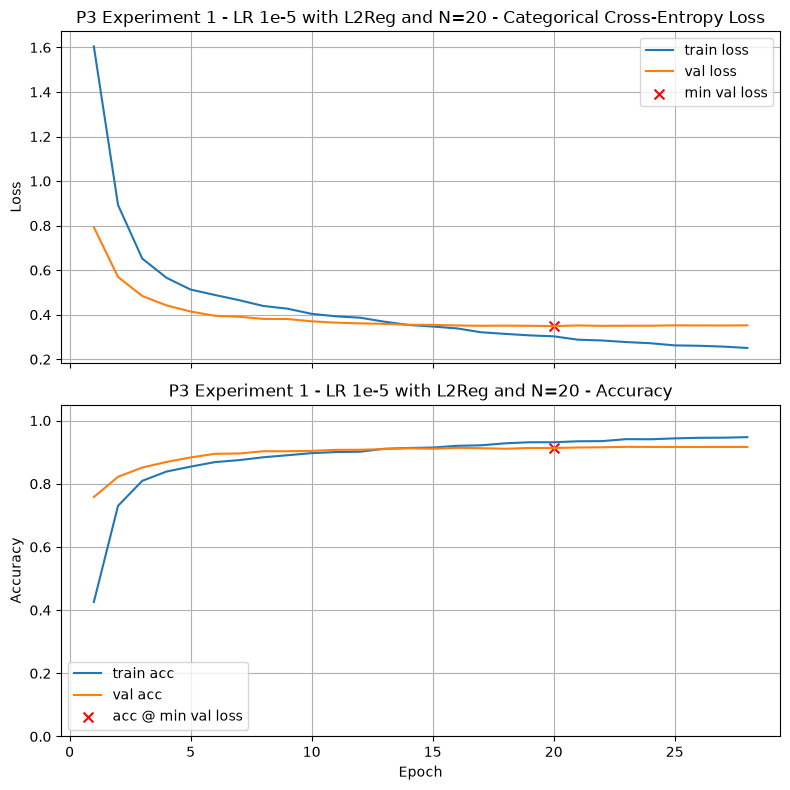

Final Training Loss:            0.2507
Final Training Accuracy:        0.9476
Final Validation Loss:          0.3522
Final Validation Accuracy:      0.9165
Minimum Validation Loss:        0.3488 (Epoch 20)
Validation Accuracy @ Min Loss: 0.9133

Test Loss: 0.3496
Test Accuracy: 0.9160

Validation-Test Gap (accuracy): 0.002662

Execution Time: 00:02:15


In [36]:
N = 20

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

model_p3_d1_baseline = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p3_d1_baseline, title="P3 Experiment 1 - LR 1e-5 with L2Reg and N=20", callbacks=[reduce_lr], lr_schedule=1e-5)

##### N=40

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 1 - LR 1e-5 with L2Reg and N=40

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 36ms/step - accuracy: 0.3902 - loss: 1.6635 - val_accuracy: 0.7660 - val_loss: 0.8507 - learning_rate: 1.0000e-05
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.6992 - loss: 0.9526 - val_accuracy: 0.8442 - val_loss: 0.5323 - learning_rate: 1.0000e-05
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8032 - loss: 0.6711 - val_accuracy: 0.8866 - val_loss: 0.4271 - learning_rate: 1.0000e-05
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8476 - loss: 0.5522 - val_accuracy: 0.8984 - val_loss: 0.3956 - learning_rate: 1.0000e-05
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8693 - loss: 0.4905 - val_accuracy: 0.9041 - val_loss: 0.3761 - learning_rate: 1.0000e-05
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8809 - loss: 0.4532 - val_accuracy: 0.9076 - val_loss: 0.3661 - learning_rate: 1.0000e-05
Epo

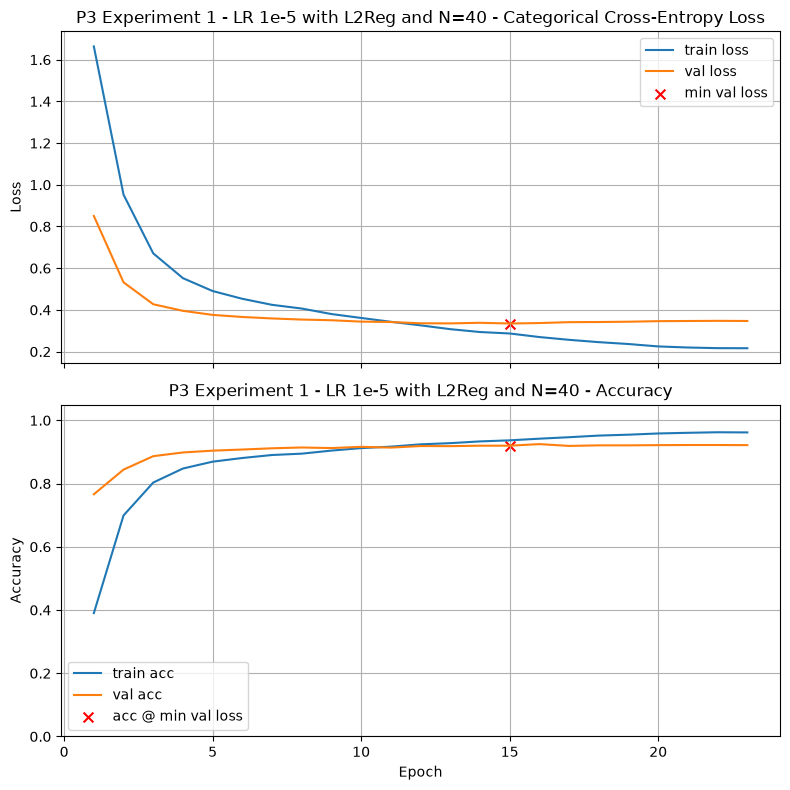

Final Training Loss:            0.2163
Final Training Accuracy:        0.9617
Final Validation Loss:          0.3470
Final Validation Accuracy:      0.9215
Minimum Validation Loss:        0.3348 (Epoch 15)
Validation Accuracy @ Min Loss: 0.9198

Test Loss: 0.3351
Test Accuracy: 0.9203

Validation-Test Gap (accuracy): 0.000576

Execution Time: 00:02:06


In [37]:
N = 40

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

model_p3_d1_n40 = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p3_d1_n40, title="P3 Experiment 1 - LR 1e-5 with L2Reg and N=40", callbacks=[reduce_lr], lr_schedule=1e-5)

##### N=80

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 1 - LR 1e-5 with L2Reg and N=80

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 44ms/step - accuracy: 0.4021 - loss: 1.6453 - val_accuracy: 0.7482 - val_loss: 0.8246 - learning_rate: 1.0000e-05
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.7045 - loss: 0.9365 - val_accuracy: 0.8520 - val_loss: 0.5128 - learning_rate: 1.0000e-05
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8024 - loss: 0.6709 - val_accuracy: 0.8830 - val_loss: 0.4388 - learning_rate: 1.0000e-05
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8443 - loss: 0.5571 - val_accuracy: 0.8941 - val_loss: 0.4090 - learning_rate: 1.0000e-05
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8675 - loss: 0.4982 - val_accuracy: 0.9048 - val_loss: 0.3841 - learning_rate: 1.0000e-05
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8843 - loss: 0.4482 - val_accuracy: 0.9044 - val_loss: 0.3762 - learning_rate: 1.0000e-05
Epo

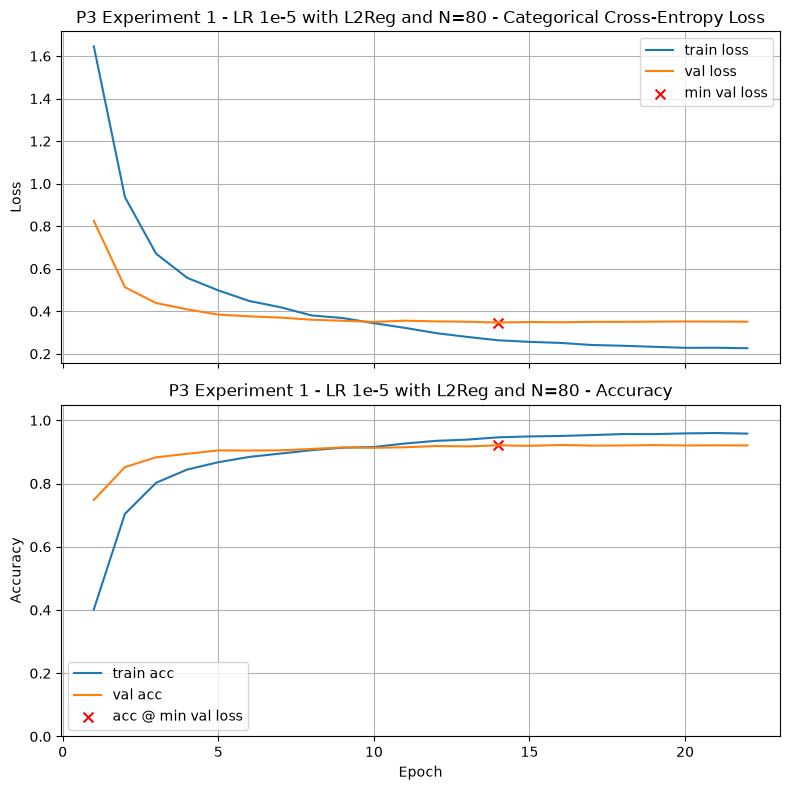

Final Training Loss:            0.2262
Final Training Accuracy:        0.9580
Final Validation Loss:          0.3510
Final Validation Accuracy:      0.9205
Minimum Validation Loss:        0.3470 (Epoch 14)
Validation Accuracy @ Min Loss: 0.9208

Test Loss: 0.3297
Test Accuracy: 0.9247

Validation-Test Gap (accuracy): 0.003839

Execution Time: 00:02:27


In [38]:
N = 80

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

model_p3_d1_n80 = models.Sequential([
    base_model,
    Dense(512, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.5),
    Dense(256, activation='relu', kernel_regularizer=l2reg),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p3_d1_n80, title="P3 Experiment 1 - LR 1e-5 with L2Reg and N=80", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 2: Varying Regularization

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 42ms/step - accuracy: 0.3724 - loss: 1.5995 - val_accuracy: 0.7407 - val_loss: 0.7706 - learning_rate: 1.0000e-05
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.6881 - loss: 0.8549 - val_accuracy: 0.8370 - val_loss: 0.4319 - learning_rate: 1.0000e-05
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.7928 - loss: 0.5860 - val_accuracy: 0.8695 - val_loss: 0.3468 - learning_rate: 1.0000e-05
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8425 - loss: 0.4595 - val_accuracy: 0.8923 - val_loss: 0.2958 - learning_rate: 1.0000e-05
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8676 - loss: 0.3820 - val_accuracy: 0.8944 - val_loss: 0.2764 - learning_rate: 1.0000e-05
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8806 - loss: 0.3488 - val_accuracy: 0.9066 - val_loss: 0.2595 - learning_rate: 1.

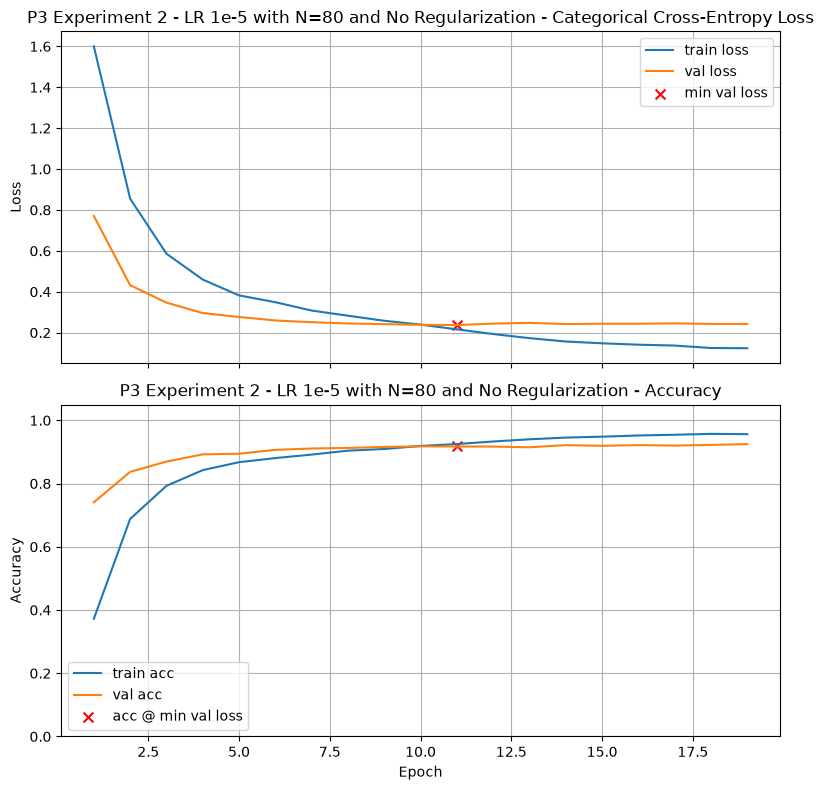

Final Training Loss:            0.1238
Final Training Accuracy:        0.9563
Final Validation Loss:          0.2427
Final Validation Accuracy:      0.9248
Minimum Validation Loss:        0.2371 (Epoch 11)
Validation Accuracy @ Min Loss: 0.9173

Test Loss: 0.2256
Test Accuracy: 0.9213

Validation-Test Gap (accuracy): 0.004072

Execution Time: 00:02:10


In [39]:
N = 80

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

model_p3_d2_no_reg = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p3_d2_no_reg, title="P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 3: Vary LR

##### 5e-4

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P3 Experiment 3 - LR 5e-4 with N=80 and No Regularization

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.8481 - loss: 0.4627 - val_accuracy: 0.7093 - val_loss: 1.6617 - learning_rate: 5.0000e-04
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9076 - loss: 0.2819 - val_accuracy: 0.8566 - val_loss: 0.7843 - learning_rate: 5.0000e-04
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9272 - loss: 0.2365 - val_accuracy: 0.7800 - val_loss: 1.6369 - learning_rate: 5.0000e-04
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9401 - loss: 0.1960 - val_accuracy: 0.7899 - val_loss: 1.5792 - learning_rate: 5.0000e-04
Epoch 5/500
349/351 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9484 - loss: 0.1531
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9484 - loss: 0.1537 - val_accuracy: 0.6715 - val_loss: 2.8307 - learning_rate: 5.0000e-

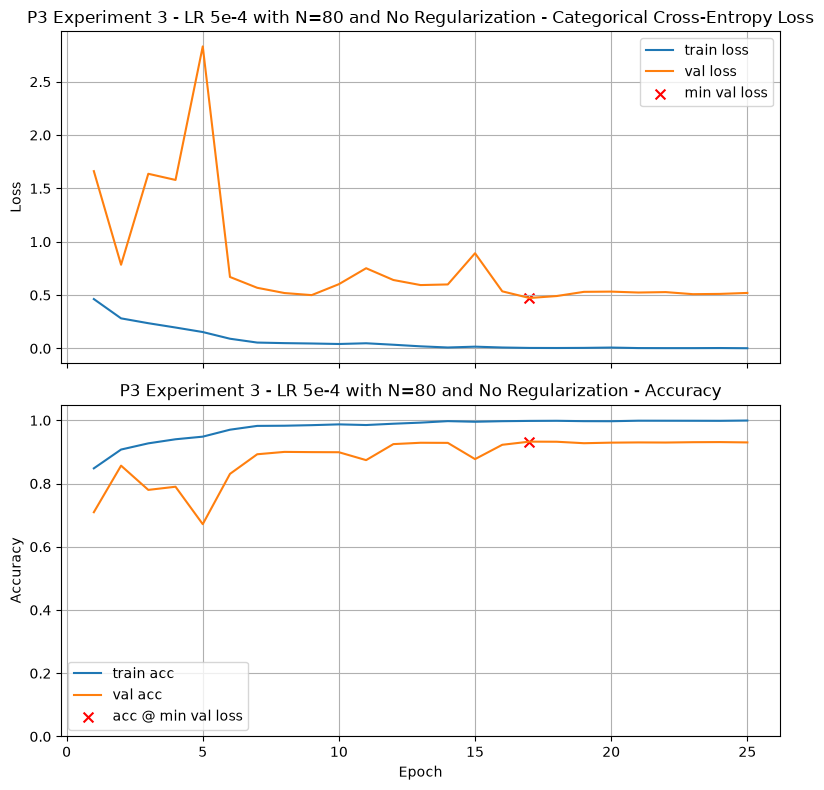

Final Training Loss:            0.0020
Final Training Accuracy:        0.9993
Final Validation Loss:          0.5202
Final Validation Accuracy:      0.9301
Minimum Validation Loss:        0.4728 (Epoch 17)
Validation Accuracy @ Min Loss: 0.9326

Test Loss: 0.5168
Test Accuracy: 0.9250

Validation-Test Gap (accuracy): 0.007596

Execution Time: 00:02:47


In [40]:
N = 80

base_model = make_base_model_pooled()
base_model.trainable = True

for layer in base_model.layers[:-N]:
    layer.trainable = False

model_p3_d3_lr_5e4 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p3_d3_lr_5e4, title="P3 Experiment 3 - LR 5e-4 with N=80 and No Regularization", callbacks=[reduce_lr], lr_schedule=5e-4)

### Graded Questions

The reflection question is worth 5 points, and the validation accuracy question is worth 15 points. 

**Reflection Question:**

Which partial-unfreezing configuration worked best for you, and what does that suggest about the effect of unfreezing the last \(N\) layers of MobileNetV2?

**Instructions:**

* Write a single paragraph (3–5 sentences).
* Explain your reasoning in choosing your three experimental designs.
* Identify the experiment that performed best.
* Briefly compare it with the other experiments, referring to both architectural choices (especially the **number \(N\) of unfrozen layers**, as well as dense layers or dropout) and training hyperparameters (e.g., learning rate, `ReduceLROnPlateau`).
* Explain which differences you think were most important, based on the training and validation behavior you observed.
* Conclude with what your experiments suggest about how much of a pretrained backbone should be unfrozen during fine-tuning.



I implemented three experiments, varying the number of layers to unfreeze, with/without l2 regularization, and the learning rate. I found that varying the number of layers to unfreeze was the most important to the model performance. This provided a best validation accuracy at the minimal loss of 0.9208 at N=80, a decrease ~0.01 over the previous optimal model (0.9219) which was entirely unfroze. Next, I built on this optimal N by attempting to remove l2 regularization which further decreased performance to 0.9173. Finally, I attempted to vary the learning rate to 5e-4, but this collapsed the model performance. Therefore, the model with l2 regularization and N=80 was the best performer.

Based on these results, I found it is important to retain a low learning rate when unfreezing a high amount of layers of the network (such as N=80). I can conclude that unfreezing N layers rather than the whole network did allow for consistent model performance, but learning rate is still critical to be mindful of. Learning rate could likely be increased if only unfreezing a small number of layers.

**Validation accuracy here (15 pts):**

In [41]:
# Set a3 to the validation accuracy found by your best model for this problem. 

a3 = 0.9208             # Replace 0.0 with your answer

In [42]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a3 = {a3:.4f}') 

a3 = 0.9208


## Problem Four — Unfreezing Convolution Blocks

**Goal.** Fine-tune MobileNetV2 by unfreezing the **last $K$ convolutional stages/blocks** rather than the last $N$ individual layers, as in Problem 3. This provides a more meaningful way to control how much of the pretrained backbone is allowed to adapt.

**Setup.** The backbone is MobileNetV2 with `include_top=False` and `pooling="avg"`, so it outputs a **1280-D feature vector**. Do **not** add another pooling layer in the head.

After creating the backbone, unfreeze the top $K$ stages using the following approach:

```python
block_prefixes = [
    "block_1", "block_2", "block_3", "block_4",
    "block_5", "block_6", "block_7", "block_8",
    "block_9", "block_10", "block_11", "block_12",
    "block_13", "block_14", "block_15", "block_16",
    "Conv_1",   # final 1×1 convolution stage before pooling
]

K = 3

base_model = make_base_model_pooled(trainable=False)

# Allow selected layers to be made trainable
base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        # Often recommended to keep BN frozen during fine-tuning
        layer.trainable = False
    else:
        layer.trainable = any(
            layer.name.startswith(prefix)
            for prefix in block_prefixes[-K:]
        )
```

For example:

* $K=1$ unfreezes only `Conv_1`.
* $K=2$ unfreezes `block_16` and `Conv_1`.
* $K=3$ unfreezes `block_15`, `block_16`, and `Conv_1`.

### To Do

1. **Design at least three experiments** in which the **last $K$ stages are unfrozen**. Vary one or more of the following:

   * $K \in {1, 2, 3, 5}$
     *(Here, $K$ counts stages/blocks, not individual Keras layers.)*
   * **BatchNormalization strategy:** keep BN frozen vs. allow BN layers in the selected blocks to be trainable.
   * **Head architecture** (select one from Problem 1).
   * **Learning rate**
   * **EarlyStopping** parameters
   * **Regularization:** Dropout and/or L2
   * **ReduceLROnPlateau:** on vs. off

2. **Run and compare** the experiments using a reduced value of `DATA_FRACTION`, focusing on:

   * how performance changes as more blocks are unfrozen,
   * whether making BatchNormalization layers trainable helps or destabilizes training,
   * training stability and convergence,
   * and validation performance trends.

   Use these runs to **understand the effect of block-level fine-tuning** and to narrow down reasonable configurations, rather than to identify a single globally optimal setting.

3. **Select one configuration** (choice of $K$, BatchNormalization strategy, and training strategy), set:

```python
DATA_FRACTION = 1.0
```

and rerun the notebook on the full dataset. Use this run when answering the graded questions.

### Notes

* Your backbone was built with `pooling="avg"`, so **do not** add another `GlobalAveragePooling2D()` layer.
* Unfreezing more blocks generally makes training **more sensitive to the learning rate** and may increase instability; this is part of what you are investigating.
* Learning rates around $1\times10^{-5}$ to $3\times10^{-5}$ are reasonable starting points for block-level fine-tuning.
* Small shifts in relative performance between reduced-data experiments and the full dataset are expected.
* Construct a **new backbone/model for each experiment** so that experiments do not inherit weights from previous runs.



#### Experiment 1: K=1

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P4 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=1

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.4413 - loss: 1.5235 - val_accuracy: 0.8384 - val_loss: 0.6148 - learning_rate: 1.0000e-05
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7331 - loss: 0.7546 - val_accuracy: 0.8773 - val_loss: 0.3853 - learning_rate: 1.0000e-05
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8016 - loss: 0.5533 - val_accuracy: 0.8887 - val_loss: 0.3242 - learning_rate: 1.0000e-05
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8296 - loss: 0.4770 - val_accuracy: 0.8934 - val_loss: 0.3032 - learning_rate: 1.0000e-05
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8533 - loss: 0.4222 - val_accuracy: 0.9005 - val_loss: 0.2881 - learning_rate: 1.0000e-05
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8627 - loss: 0.3851 - val_accuracy: 0.8998 - val_loss: 0.2805 - learning_

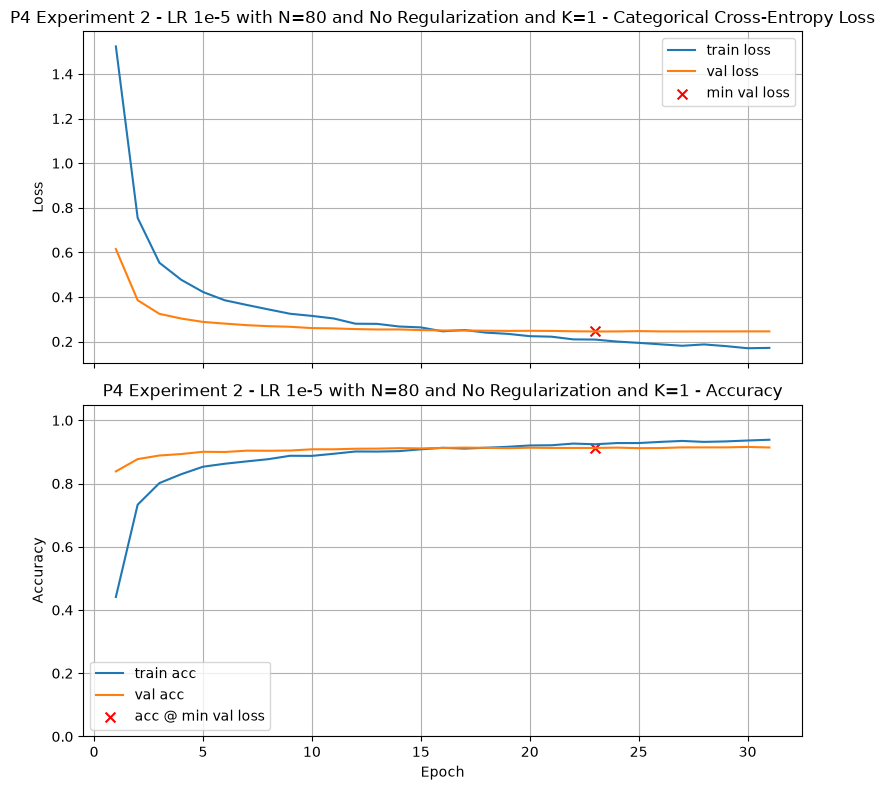

Final Training Loss:            0.1716
Final Training Accuracy:        0.9386
Final Validation Loss:          0.2457
Final Validation Accuracy:      0.9141
Minimum Validation Loss:        0.2451 (Epoch 23)
Validation Accuracy @ Min Loss: 0.9126

Test Loss: 0.2317
Test Accuracy: 0.9140

Validation-Test Gap (accuracy): 0.001375

Execution Time: 00:02:11


In [43]:
block_prefixes = [
    "block_1", "block_2", "block_3", "block_4",
    "block_5", "block_6", "block_7", "block_8",
    "block_9", "block_10", "block_11", "block_12",
    "block_13", "block_14", "block_15", "block_16",
    "Conv_1",   # final 1×1 convolution stage before pooling
]

K = 1

base_model = make_base_model_pooled(trainable=False)

# Allow selected layers to be made trainable
base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        # Often recommended to keep BN frozen during fine-tuning
        layer.trainable = False
    else:
        layer.trainable = any(
            layer.name.startswith(prefix)
            for prefix in block_prefixes[-K:]
        )

model_p4_d1_k1 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p4_d1_k1, title="P4 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=1", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 2: K=3

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P4 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=3

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.5944 - loss: 1.0925 - val_accuracy: 0.8773 - val_loss: 0.3636 - learning_rate: 1.0000e-05
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8213 - loss: 0.5030 - val_accuracy: 0.8937 - val_loss: 0.3057 - learning_rate: 1.0000e-05
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8613 - loss: 0.3967 - val_accuracy: 0.9012 - val_loss: 0.2851 - learning_rate: 1.0000e-05
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8813 - loss: 0.3470 - val_accuracy: 0.9076 - val_loss: 0.2707 - learning_rate: 1.0000e-05
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8937 - loss: 0.3117 - val_accuracy: 0.9116 - val_loss: 0.2533 - learning_rate: 1.0000e-05
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8994 - loss: 0.2844 - val_accuracy: 0.9137 - val_loss: 0.2510 - learning_

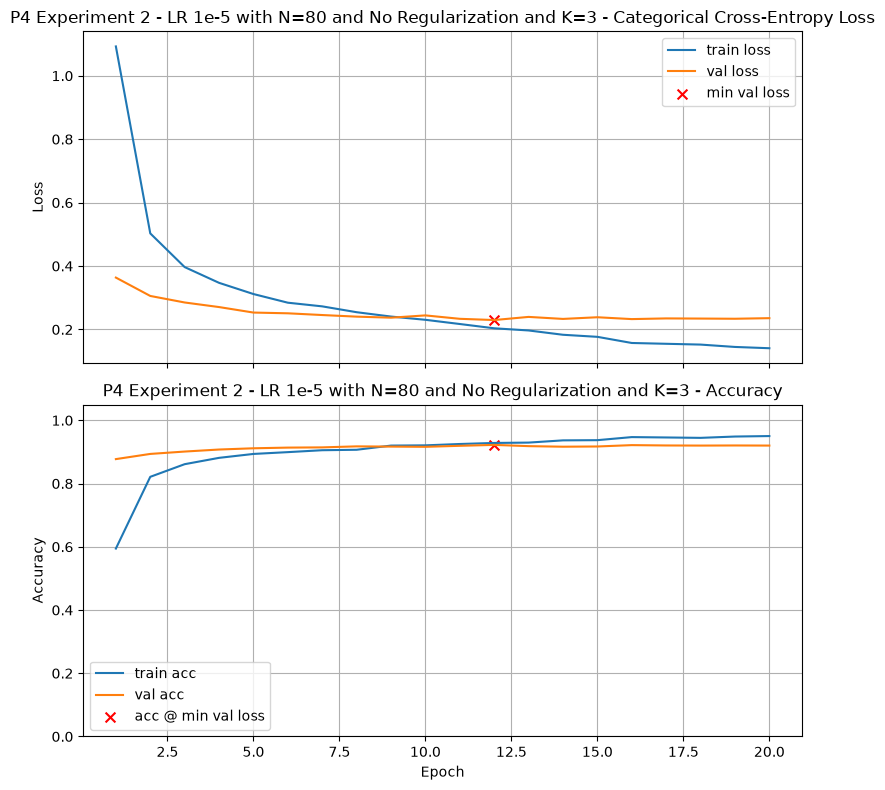

Final Training Loss:            0.1409
Final Training Accuracy:        0.9502
Final Validation Loss:          0.2357
Final Validation Accuracy:      0.9201
Minimum Validation Loss:        0.2297 (Epoch 12)
Validation Accuracy @ Min Loss: 0.9223

Test Loss: 0.2163
Test Accuracy: 0.9263

Validation-Test Gap (accuracy): 0.004079

Execution Time: 00:01:38


In [44]:
block_prefixes = [
    "block_1", "block_2", "block_3", "block_4",
    "block_5", "block_6", "block_7", "block_8",
    "block_9", "block_10", "block_11", "block_12",
    "block_13", "block_14", "block_15", "block_16",
    "Conv_1",   # final 1×1 convolution stage before pooling
]

K = 3

base_model = make_base_model_pooled(trainable=False)

# Allow selected layers to be made trainable
base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        # Often recommended to keep BN frozen during fine-tuning
        layer.trainable = False
    else:
        layer.trainable = any(
            layer.name.startswith(prefix)
            for prefix in block_prefixes[-K:]
        )

model_p4_d1_k3 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p4_d1_k3, title="P4 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=3", callbacks=[reduce_lr], lr_schedule=1e-5)

#### Experiment 3: K=5

/tmp/ipykernel_2412/3444387780.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = mobilenet_v2.MobileNetV2(



P4 Experiment 3 - LR 1e-5 with N=80 and No Regularization and K=5

Epoch 1/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 17s 31ms/step - accuracy: 0.6154 - loss: 1.0179 - val_accuracy: 0.8912 - val_loss: 0.3357 - learning_rate: 1.0000e-05
Epoch 2/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8535 - loss: 0.4143 - val_accuracy: 0.9034 - val_loss: 0.2838 - learning_rate: 1.0000e-05
Epoch 3/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8840 - loss: 0.3368 - val_accuracy: 0.9094 - val_loss: 0.2699 - learning_rate: 1.0000e-05
Epoch 4/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8982 - loss: 0.2940 - val_accuracy: 0.9148 - val_loss: 0.2538 - learning_rate: 1.0000e-05
Epoch 5/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9103 - loss: 0.2671 - val_accuracy: 0.9058 - val_loss: 0.2566 - learning_rate: 1.0000e-05
Epoch 6/500
351/351 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9191 - loss: 0.2451 - val_accuracy: 0.9173 - val_loss: 0.2407 - learning_

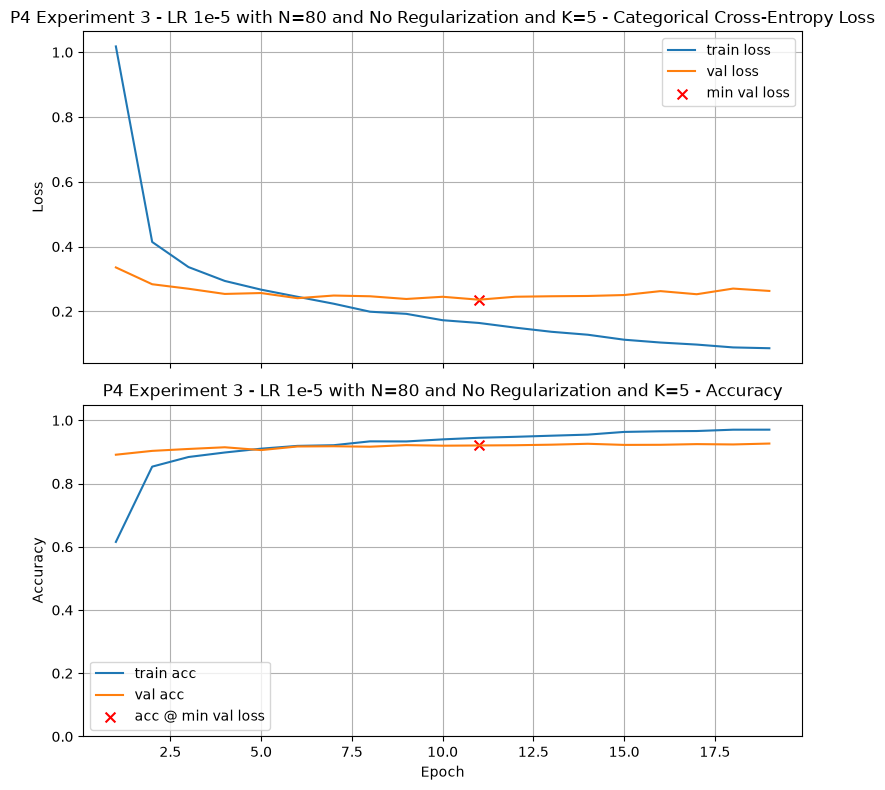

Final Training Loss:            0.0862
Final Training Accuracy:        0.9704
Final Validation Loss:          0.2631
Final Validation Accuracy:      0.9265
Minimum Validation Loss:        0.2361 (Epoch 11)
Validation Accuracy @ Min Loss: 0.9205

Test Loss: 0.2109
Test Accuracy: 0.9290

Validation-Test Gap (accuracy): 0.008529

Execution Time: 00:01:39


In [45]:
block_prefixes = [
    "block_1", "block_2", "block_3", "block_4",
    "block_5", "block_6", "block_7", "block_8",
    "block_9", "block_10", "block_11", "block_12",
    "block_13", "block_14", "block_15", "block_16",
    "Conv_1",   # final 1×1 convolution stage before pooling
]

K = 5

base_model = make_base_model_pooled(trainable=False)

# Allow selected layers to be made trainable
base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        # Often recommended to keep BN frozen during fine-tuning
        layer.trainable = False
    else:
        layer.trainable = any(
            layer.name.startswith(prefix)
            for prefix in block_prefixes[-K:]
        )

model_p4_d1_k5 = models.Sequential([
    base_model,
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

train_and_test(model_p4_d1_k5, title="P4 Experiment 3 - LR 1e-5 with N=80 and No Regularization and K=5", callbacks=[reduce_lr], lr_schedule=1e-5)

### Graded Questions

The reflection question is worth 5 points, and the validation accuracy question is worth 15 points. 

**Reflection Question:**

Which block-unfreezing configuration worked best for you, and what does that suggest about the effect of unfreezing the last \(K\) MobileNetV2 blocks?

**Instructions:**

* Write a single paragraph (3–5 sentences).
* Explain your reasoning in choosing your three experimental designs.
* Identify the experiment that performed best.
* Briefly compare it with the other experiments, referring to both architectural choices (especially the **number \(K\) of unfrozen blocks**, as well as dense layers or dropout) and training hyperparameters (e.g., learning rate, `ReduceLROnPlateau`).
* If you experimented with BatchNormalization, comment briefly on whether keeping BN frozen or allowing it to train appeared to help or destabilize training.
* Explain which differences you think were most important, based on the training and validation behavior you observed.
* Conclude with what your experiments suggest about selecting how many pretrained blocks to unfreeze during fine-tuning.



After attempting three experiments, varying K=1, K=3 and K=5, I found that K=5 was the best performing model. This model achieved 0.9205 validation accuracy in 12 epochs in comparison to 0.9223 at K=3 and 0.9126 at K=1. Across runs with smaller counts of data K=5 achieved stronger consistent performance, so I opted to use it despite less validation accuracy than K=3 in my final run. This shows that increasing the number of MobileNetV2 blocks improved the generalization on our specific domain of images. The layers were able to learn the class specific patterns better and the early layers were able to retain their ability to extract features. Varying K provided the strongest performance across all experiments in this project, showing on this specific dataset the targetted convolutional layer unfreezing performed better than unfreezing the entire model or a specific number of layers.

**Validation accuracy (15pts):**

In [53]:
# Set a4 to the validation accuracy found by your best model for this problem. 

a4 = 0.9205             # Replace 0.0 with your answer

In [54]:
# Graded Answer
# DO NOT change this cell in any way          

print(f'a4 = {a4:.4f}') 

a4 = 0.9205


## Problem 5: Final Reflection

Run the next cell and consider all your experiments in this homework. 

This reflection question is worth 5 points. 

In [55]:
# Print out summary of validation accuracy for each experiment

print_results()

P3 Experiment 3 - LR 5e-4 with N=80 and No Regularization	0.9326	17
P4 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=3	0.9223	12
P2 Experiment 1 - LR 1e-5, L2Reg, and no ReduceLROnPlateau	0.9219	11
P3 Experiment 1 - LR 1e-5 with L2Reg and N=80	0.9208	14
P4 Experiment 3 - LR 1e-5 with N=80 and No Regularization and K=5	0.9205	11
P3 Experiment 1 - LR 1e-5 with L2Reg and N=40	0.9198	15
P2 Experiment 1 - LR 1e-5 with L2Reg    	0.9194	12
P3 Experiment 2 - LR 1e-5 with N=80 and No Regularization	0.9173	11
P2 Experiment 1 - LR 1e-5               	0.9155	12
P1 Design 2. Dense-Dropout-Dense-Dropout lr 1e-4	0.9137	9
P3 Experiment 1 - LR 1e-5 with L2Reg and N=20	0.9133	20
P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm and L2 Reg 1e-3	0.9126	32
P4 Experiment 2 - LR 1e-5 with N=80 and No Regularization and K=1	0.9126	23
P1 Design 1. Dense 256 with Dropout     	0.9119	5
P2 Experiment 1 - LR Baseline           	0.9116	24
P1 Design 3. Dense-Dropout-Dense-Dropout with BatchNorm 

### Graded Question

### Final Reflection

Looking across the validation accuracies from your **full-dataset runs**, what patterns or lessons stand out from the different transfer-learning strategies you explored?

**Instructions:**

* Write a single paragraph (3–5 sentences).
* Compare the overall results from the frozen backbone, fully trainable backbone, partial layer unfreezing, and block-level unfreezing experiments.
* Highlight at least one design choice or training hyperparameter that appeared especially important.
* Mention any result that surprised you or differed from what you expected, if applicable.
* Conclude with a brief takeaway about what you learned about transfer learning from the homework.



The primary lesson I learned in the transfer learning project is the importance of carefully considering a learning rate and learning decay strategy when evaluating models. I found throughout the frozen backbone, fully trainable backbone, partial layer unfreezing, and block level unfreezing that learning rate could collapse the model when I raised it higher than 1e-5. Additionally, I found that modifying the learning rate on plateau helped in final convergence. Additionally, an important learning was the power of block level unfreezing. By tuning the number of K I was able to achieve the best performance across all experiments, by allowing the convolutional layers to learning domain specific feature patterns. Finally, I was surprised to see in Problem 1 that simple models actually performed on par with more complex architectures in the frozen backbone, showing that more deep modifications to the backbone were needed to lift performance. Just varying the head architecture was not a strong indicator of performance early on. Overall, I learned the power of using transfer learning to tune pre-trained models to domain specific datasets. From the initial baseline, I was able to lift the validation accuracy from 0.8994 to 0.9205, which can be impactful in real world scenarios.

## Appendix: What is MobileNetV2 (in plain English)?

`MobileNetV2` is a lightweight convolutional neural network (CNN) designed for efficient inference on resource-constrained devices while maintaining strong image-classification accuracy.

It achieves this with two important ideas:

1. **Depthwise-separable convolutions**

   Instead of using one expensive 3×3 convolution that mixes spatial information and channels at the same time, MobileNetV2 separates the operation into two steps:

   * a **depthwise 3×3 convolution**, which applies one spatial filter to each input channel separately, followed by
   * a **pointwise 1×1 convolution**, which mixes information across channels.

   This greatly reduces the number of parameters and computations compared with a standard convolution. ([arXiv][1])

2. **Inverted residual blocks with a linear bottleneck**

   A typical MobileNetV2 block has the following structure:

   * **Expand (1×1 convolution):** increase the number of channels, often by a factor of about 6, and apply a nonlinear activation.
   * **Depthwise (3×3 convolution):** process each channel separately and apply a nonlinear activation.
   * **Project (1×1 convolution):** reduce the number of channels again, but **without** applying a nonlinear activation. This is the **linear bottleneck**.

   If the input and output shapes match and the stride is 1, the block also adds a **skip connection**.

   The term **inverted residual** refers to the fact that the representation becomes wide inside the block and narrow again at the output, rather than the other way around.

   The final linear projection helps preserve information when the representation is compressed back to a lower-dimensional space. ([arXiv][1])

---

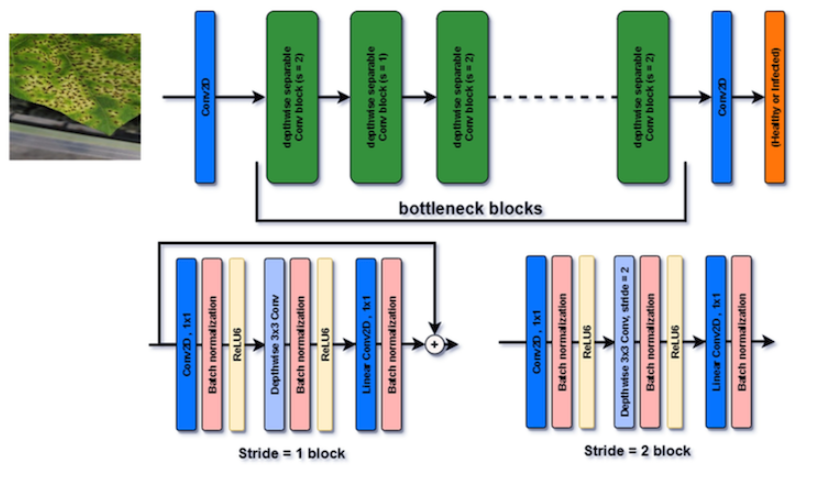

---

### What was MobileNetV2 trained on?

The Keras ImageNet weights for MobileNetV2 were trained on **ImageNet-1K**, a standard image-classification dataset containing:

* **1,281,167** training images
* **50,000** validation images
* **100,000** test images
* **1000 classes**

A common input size for MobileNetV2 is **224×224**. ([ImageNet][2])

For this homework, we use smaller **150×150** images to reduce training time.

Because we use:

```python
include_top=False
```

the pretrained convolutional backbone can operate on image sizes other than 224×224.

---

### Preprocessing

The preprocessing used for a pretrained network should match the preprocessing used when that network was originally trained.

For MobileNetV2, Keras provides:

```python
mobilenet_v2.preprocess_input
```

This function takes pixel values in their original approximately **0–255** range and scales them to approximately **[-1, 1]**.

In this homework, the image-loading pipeline applies this preprocessing before passing images to MobileNetV2. ([keras.io][3])

---

### How Keras exposes MobileNetV2

The following Keras call:

```python
tf.keras.applications.mobilenet_v2.MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg"
)
```

returns a pretrained MobileNetV2 backbone with the original ImageNet classification head removed.

With:

```python
pooling="avg"
```

Keras applies **Global Average Pooling** to the final convolutional feature map. The result is a **1280-dimensional feature vector** for each image.

To use this backbone as a **frozen feature extractor**, we additionally set:

```python
base_model.trainable = False
```

The classification head that we add afterward can then be trained while the pretrained MobileNetV2 weights remain unchanged.

---

### What happens if `pooling="avg"` is omitted?

Without pooling, the backbone produces a spatial feature map rather than a single feature vector.

For a 224×224 input image, this feature map is typically:

```text
7 × 7 × 1280
```

Before connecting this to Dense layers, we would normally reduce the spatial dimensions using:

```python
GlobalAveragePooling2D()
```

which produces a 1280-dimensional vector.

`GlobalMaxPooling2D()` is another possible choice.

Using:

```python
Flatten()
```

is usually less attractive here because it would convert:

```text
7 × 7 × 1280
```

into:

```text
62,720
```

features, creating a much larger classification head.

In this homework, however, we use:

```python
pooling="avg"
```

inside MobileNetV2 itself, so **do not add another `GlobalAveragePooling2D()` layer**.

---

### How we use MobileNetV2 in this homework

We will experiment with several ways of using the pretrained backbone:

* **Frozen feature extraction:** keep all MobileNetV2 layers frozen and train only a new classification head.
* **Fully trainable backbone:** allow all MobileNetV2 layers to be updated during training.
* **Partial unfreezing:** keep most of the backbone frozen while allowing only selected upper layers or blocks to be updated.

These experiments let us investigate how much of the pretrained representation should be preserved and how much should be adapted to the Intel Image Classification dataset.

---

### TL;DR Summary

* Think of a MobileNetV2 block as:

  **expand → depthwise convolution → project (+ optional skip connection)**

* MobileNetV2 was pretrained to distinguish **1000 ImageNet classes**.

* In this homework, we reuse those learned visual features and train the model for our **6 Intel image classes**.

* With:

  ```python
  include_top=False,
  pooling="avg"
  ```

  the backbone outputs a **1280-D feature vector**.

* To use the backbone as a frozen feature extractor, set:

  ```python
  base_model.trainable = False
  ```

* Always match preprocessing to the pretrained backbone. For MobileNetV2, use:

  ```python
  mobilenet_v2.preprocess_input
  ```

  which scales the original pixel values to approximately **[-1, 1]**. ([keras.io][3])

---

### See also

* [https://www.analyticsvidhya.com/blog/2023/12/what-is-mobilenetv2/](https://www.analyticsvidhya.com/blog/2023/12/what-is-mobilenetv2/)

[1]: https://arxiv.org/abs/1801.04381
[2]: https://www.image-net.org/
[3]: https://keras.io/api/applications/mobilenet/mobilenet_models/


